# Time-to-Event Customer Churn Survival Analysis Using 4-Criterion Non-Linear Feature Selection and a Multi-Paradigm Ensemble

This repository presents an end-to-end survival analysis and churn forecasting framework applied to longitudinal digital financial transaction and daily balance records over a 91-day observation horizon. Rather than relying on dense kernel projections or retaining redundant collinear predictors, this pipeline performs fold-isolated, consensus-based non-linear feature selection before fitting a multi-paradigm survival ensemble under jointly stratified 5-fold cross-validation.

### Methodological Architecture

1. **Survival Evaluation Under Right-Censoring:** Standard classification metrics misrepresent risk discrimination when accounts remain active beyond the observation boundary. We implement exact Harrell's concordance index (C-index) in $O(n \log n)$ time via a Fenwick tree (`_FenwickTree`), Kaplan-Meier survival schedules, two-sample log-rank hypothesis tests, and Inverse Probability of Censoring Weighted (IPCW) Brier and Integrated Brier Scores (IBS) across horizons $t \in \{30, 60, 90\}$ days.
2. **High-Throughput Longitudinal Feature Engineering:** Anchored strictly at the observation cutoff (`2024-03-31`), consolidated lazy `Polars` aggregations over outgoing (`SRC_ACCOUNT`) and non-self incoming (`DST_ACCOUNT`) transactions, daily balance drawdowns, and `kyc` cohort encodings capture behavioral velocity decay and liquidity stress without temporal leakage.
3. **Fold-Isolated 4-Criterion Non-Linear Feature Selection (`_select_nonlinear_features_fold`):** Inside each training fold (`tr_i`), constant variables are removed (`std <= 1e-8`) and candidate predictors are scored against eight random permutation shadow variables across four complementary non-linear criteria:
   * **Mutual Information (`mutual_info_classif`)**: Quantifies non-monotonic statistical dependency $I(X_j; Y_{90})$ on stratified subsamples.
   * **Shadow-Gated `LightGBM` Gain**: Isolates non-linear tree split interactions exceeding the 85th percentile of shadow noise.
   * **Shadow-Gated `XGBoost` Cox PH Gain (`survival:cox`)**: Captures time-to-event non-linearity conditioned on censored `DURATION_DAYS`.
   * **Shadow-Gated `RandomForestClassifier` Impurity Importance**: Adds bagging-based variance resistance against boosting bias.
4. **Multi-Paradigm Survival Ensemble, Tabular Reports, and Visual Diagnostics:** Selected fold subsets train multi-horizon `LightGBM` ($\{30, 60, 75, 83, 90\}$ days), `CatBoost` ($\{60, 90\}$ days), binary/AFT/Cox `XGBoost`, and regularized `RandomForestClassifier`, followed by Level-2 meta-stacking (`L2_LGB_Meta`, `L2_XGB_Cox_Meta`, `L2_RF_Meta`), Powell simplex optimization, and monotonic probability calibration ($S(30) \ge S(60) \ge S(90)$). Experimental diagnostics persist to styled evaluation tables (`nonlinear_fs_ensemble_metrics.csv`, `nonlinear_feature_selection_report.csv`) and visualizations (`feature_domain_composition.png`, `ensemble_evaluation_diagnostics.png`, `feature_selection_and_calibration.png`).

## 1. Environment Configuration, Hardware Detection, and Survival Metrics

This section initializes deterministic random seeds, probes available GPU/CPU backends (`CUDA` for `XGBoost` and `CatBoost`), and defines self-contained, exact implementations of survival analysis metrics. To guarantee portability across offline or minimal compute environments, `exact_concordance_index_censored`, `exact_ipcw_brier_at_times`, `exact_integrated_brier_score`, `kaplan_meier_table`, and `logrank_test_2sample` are implemented directly in `NumPy` and `SciPy` with an $O(n \log n)$ Fenwick tree for censored concordance evaluation.

In [1]:
import os, sys, gc, glob, math, time, random, warnings, subprocess
from pathlib import Path
from datetime import timedelta, date
import datetime as dt

warnings.filterwarnings("ignore")


def _install_if_missing(pkgs):
    try:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *pkgs],
            check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
        )
    except Exception:
        pass


for mod, pkg in [("polars", "polars"), ("lightgbm", "lightgbm"), ("xgboost", "xgboost")]:
    try:
        __import__(mod)
    except ImportError:
        _install_if_missing([pkg])

import numpy as np
import pandas as pd
import polars as pl
import lightgbm as lgb
import xgboost as xgb
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

try:
    from IPython.display import display, HTML
    HAS_IPYTHON = True
except Exception:
    HAS_IPYTHON = False

HAS_CATBOOST = False
try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
except Exception:
    pass

# Probe GPU availability directly via minimal test fits to guarantee fallback safety
HAS_XGB_CUDA = False
HAS_CB_GPU = False
try:
    _res = subprocess.run(["nvidia-smi"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False)
    if _res.returncode == 0:
        try:
            _dm = xgb.DMatrix(np.random.randn(16, 4).astype(np.float32), label=np.array([0, 1] * 8))
            xgb.train({"tree_method": "hist", "device": "cuda", "max_depth": 2}, _dm, num_boost_round=2, verbose_eval=False)
            HAS_XGB_CUDA = True
        except Exception:
            pass
        if HAS_CATBOOST:
            try:
                _cb = CatBoostClassifier(iterations=2, depth=2, task_type="GPU", verbose=False)
                _cb.fit(np.random.randn(16, 4), np.array([0, 1] * 8))
                HAS_CB_GPU = True
            except Exception:
                pass
except Exception:
    pass
HAS_CUDA = HAS_XGB_CUDA or HAS_CB_GPU

# Probe survival metric backends; fall back to exact NumPy implementations when offline
HAS_SKSURV = False
try:
    from sksurv.util import Surv as _SksurvSurv
    from sksurv.metrics import (
        concordance_index_censored as _sk_cindex,
        integrated_brier_score as _sk_ibs,
    )
    HAS_SKSURV = True
except Exception:
    pass

HAS_LIFELINES = False
try:
    from lifelines.statistics import logrank_test as _lifelines_logrank
    HAS_LIFELINES = True
except Exception:
    pass

# Publication-grade Matplotlib configuration
plt.rcParams.update({
    "figure.dpi": 135,
    "savefig.dpi": 180,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "legend.framealpha": 0.92,
    "legend.edgecolor": "#e2e8f0",
    "grid.color": "#cbd5e1",
    "grid.linestyle": "--",
    "grid.alpha": 0.45,
})


def _style_ax(ax, grid_axis="y"):
    """Apply clean academic axis styling with despined top/right borders."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if grid_axis in ("x", "y", "both"):
        ax.grid(axis=grid_axis, alpha=0.4)


def display_table(
    df: pd.DataFrame,
    title: str = None,
    fmt: dict = None,
    max_cols_highlight: list = None,
    min_cols_highlight: list = None,
):
    """Render a publication-styled HTML table in Jupyter/Kaggle with clean CLI fallback."""
    in_notebook = False
    if HAS_IPYTHON:
        try:
            from IPython import get_ipython
            in_notebook = get_ipython() is not None and "IPKernelApp" in getattr(get_ipython(), "config", {})
        except Exception:
            in_notebook = False

    if in_notebook:
        if title:
            display(HTML(f"<h4 style='margin:14px 0 6px 0;color:#0f172a;font-family:sans-serif;'>{title}</h4>"))
        styler = df.style.hide(axis="index")
        if fmt:
            styler = styler.format(fmt, na_rep="-")
        if max_cols_highlight:
            valid_max = [c for c in max_cols_highlight if c in df.columns]
            if valid_max:
                styler = styler.highlight_max(subset=valid_max, color="#dcfce7")
        if min_cols_highlight:
            valid_min = [c for c in min_cols_highlight if c in df.columns]
            if valid_min:
                styler = styler.highlight_min(subset=valid_min, color="#dbeafe")
        styler = styler.set_table_styles([
            {"selector": "table", "props": [("border-collapse", "collapse"), ("font-size", "12.5px"), ("margin-bottom", "10px")]},
            {"selector": "th", "props": [("background-color", "#1e293b"), ("color", "#ffffff"), ("font-weight", "600"), ("padding", "7px 11px"), ("text-align", "left"), ("border-bottom", "2px solid #0f172a")]},
            {"selector": "td", "props": [("padding", "6px 11px"), ("border-bottom", "1px solid #e2e8f0")]},
            {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#f8fafc")]},
        ])
        display(styler)
    else:
        if title:
            print(f"\n=== {title} ===")
        print(df.to_string(index=False))


class _SurvFallback:
    """Structured event-time container matching sksurv.util.Surv.from_arrays."""
    @staticmethod
    def from_arrays(event, time):
        ev = np.asarray(event, dtype=bool)
        tm = np.asarray(time, dtype=float)
        return np.rec.fromarrays([ev, tm], names="event,time")


Surv = _SksurvSurv if HAS_SKSURV else _SurvFallback


class _FenwickTree:
    """1-indexed Binary Indexed Tree enabling O(N log N) censored concordance updates."""
    __slots__ = ("tree", "n")

    def __init__(self, n: int):
        self.n = n
        self.tree = np.zeros(n + 1, dtype=np.int64)

    def add(self, idx: int, val: int = 1):
        i = idx + 1
        n = self.n
        tree = self.tree
        while i <= n:
            tree[i] += val
            i += i & -i

    def prefix_sum(self, idx: int) -> int:
        if idx < 0:
            return 0
        i = idx + 1
        s = 0
        tree = self.tree
        while i > 0:
            s += tree[i]
            i -= i & -i
        return int(s)


def exact_concordance_index_censored(event_indicator, event_time, estimate):
    """Compute exact Harrell's C-index under right-censoring in O(N log N) time."""
    event = np.asarray(event_indicator, dtype=bool)
    time_arr = np.asarray(event_time, dtype=float)
    risk = np.asarray(estimate, dtype=float)

    n = len(time_arr)
    if n == 0 or event.sum() == 0:
        return (0.5, 0, 0, 0, 0)

    _, risk_ranks = np.unique(risk, return_inverse=True)
    m = int(risk_ranks.max()) + 1

    # Process descending survival times so only subjects strictly surviving longer are active in the Fenwick tree
    order = np.lexsort((event.astype(np.int8), -time_arr))
    sorted_time = time_arr[order]
    sorted_event = event[order]
    sorted_rank = risk_ranks[order]

    bit = _FenwickTree(m)
    total_added = 0
    concordant = discordant = tied_risk = tied_time = 0

    idx = 0
    while idx < n:
        cur_t = sorted_time[idx]
        j = idx
        while j < n and sorted_time[j] == cur_t:
            j += 1
        block_ev = sorted_event[idx:j]
        block_rk = sorted_rank[idx:j]

        for rk in block_rk[~block_ev]:
            bit.add(int(rk), 1)
            total_added += 1

        ev_rks = block_rk[block_ev]
        n_ev = len(ev_rks)
        if n_ev > 1:
            tied_time += n_ev * (n_ev - 1) // 2

        for rk in ev_rks:
            rk_i = int(rk)
            conc = bit.prefix_sum(rk_i - 1)
            leq = bit.prefix_sum(rk_i)
            concordant += conc
            tied_risk += leq - conc
            discordant += total_added - leq

        for rk in ev_rks:
            bit.add(int(rk), 1)
            total_added += 1
        idx = j

    denom = concordant + discordant + tied_risk
    c_idx = (concordant + 0.5 * tied_risk) / denom if denom > 0 else 0.5
    return (float(c_idx), int(concordant), int(discordant), int(tied_risk), int(tied_time))


def _km_censoring_weights(train_event, train_time):
    """Estimate Kaplan-Meier censoring survival function G(t) for IPCW weighting."""
    ev_c = ~np.asarray(train_event, dtype=bool)
    tm = np.asarray(train_time, dtype=float)
    order = np.argsort(tm)
    tm_s, ev_s = tm[order], ev_c[order]
    uniq_t, idx_start, counts = np.unique(tm_s, return_index=True, return_counts=True)
    d_c = np.add.reduceat(ev_s.astype(np.int64), idx_start)
    at_risk = len(tm_s) - np.concatenate(([0], np.cumsum(counts[:-1])))
    with np.errstate(divide="ignore", invalid="ignore"):
        surv_step = np.where(at_risk > 0, 1.0 - d_c / at_risk, 1.0)
    return uniq_t, np.cumprod(surv_step)


def _eval_step_right_continuous(times_eval, km_times, km_vals):
    idx = np.searchsorted(km_times, times_eval, side="right") - 1
    out = np.ones_like(times_eval, dtype=float)
    valid = idx >= 0
    out[valid] = km_vals[idx[valid]]
    return out


def exact_ipcw_brier_at_times(y_train, y_test, estimate, times):
    """Compute exact IPCW Brier scores at specified horizons and trapezoidal Integrated Brier Score."""
    ev_tr = np.asarray(y_train["event"], dtype=bool)
    tm_tr = np.asarray(y_train["time"], dtype=float)
    ev_te = np.asarray(y_test["event"], dtype=bool)
    tm_te = np.asarray(y_test["time"], dtype=float)
    surv_pred = np.asarray(estimate, dtype=float)
    times = np.asarray(times, dtype=float)

    km_t, G_vals = _km_censoring_weights(ev_tr, tm_tr)
    G_horizon = np.clip(_eval_step_right_continuous(times, km_t, G_vals), 1e-8, 1.0)
    G_subj_minus = np.clip(_eval_step_right_continuous(tm_te - 1e-9, km_t, G_vals), 1e-8, 1.0)

    brier_scores = np.zeros(len(times), dtype=float)
    for k, t in enumerate(times):
        s_k = surv_pred[:, k]
        is_dead = (tm_te <= t) & ev_te
        is_alive = tm_te > t
        contrib = np.zeros(len(tm_te), dtype=float)
        contrib[is_dead] = ((0.0 - s_k[is_dead]) ** 2) / G_subj_minus[is_dead]
        contrib[is_alive] = ((1.0 - s_k[is_alive]) ** 2) / G_horizon[k]
        brier_scores[k] = contrib.mean()

    if len(times) == 1:
        ibs_val = float(brier_scores[0])
    else:
        trapz_fn = getattr(np, "trapezoid", None) or np.trapz
        ibs_val = float(trapz_fn(brier_scores, times) / (times[-1] - times[0]))
    return {int(t): float(b) for t, b in zip(times, brier_scores)}, ibs_val


def concordance_index_censored(event_indicator, event_time, estimate):
    if HAS_SKSURV:
        return _sk_cindex(event_indicator, event_time, estimate)
    return exact_concordance_index_censored(event_indicator, event_time, estimate)


def integrated_brier_score(y_train, y_test, estimate, times):
    if HAS_SKSURV:
        try:
            return _sk_ibs(y_train, y_test, estimate, times)
        except Exception:
            pass
    return exact_ipcw_brier_at_times(y_train, y_test, estimate, times)[1]


def kaplan_meier_table(durations, events, max_day=91):
    """Compute discrete-day Kaplan-Meier survival probabilities with Greenwood 95% confidence bounds."""
    dur = np.asarray(durations, dtype=np.int64)
    ev = np.asarray(events, dtype=np.int64)
    rows = []
    s, greenwood_sum, cum_haz = 1.0, 0.0, 0.0
    for d in range(0, int(max_day) + 1):
        at_risk = int((dur >= d).sum())
        d_events = int(((dur == d) & (ev == 1)).sum())
        d_cens = int(((dur == d) & (ev == 0)).sum())
        if at_risk > 0 and d_events > 0:
            haz = d_events / at_risk
            s *= (1.0 - haz)
            cum_haz += haz
            denom = at_risk * (at_risk - d_events)
            if denom > 0:
                greenwood_sum += d_events / denom
        else:
            haz = 0.0
        se = s * math.sqrt(greenwood_sum) if greenwood_sum > 0 else 0.0
        rows.append({
            "day": int(d), "at_risk": at_risk, "events": d_events, "censored": d_cens,
            "hazard_rate": haz, "hazard_pct": haz * 100.0, "cum_hazard": cum_haz,
            "survival": s, "ci_lower": max(0.0, s - 1.96 * se),
            "ci_upper": min(1.0, s + 1.96 * se), "churn_cdf": 1.0 - s,
        })
    df = pd.DataFrame(rows)
    df["hazard_7d_smooth_pct"] = df["hazard_pct"].rolling(7, center=True, min_periods=1).mean()
    return df


def logrank_test_2sample(dur_a, ev_a, dur_b, ev_b):
    """Compute Mantel-Haenszel two-sample log-rank chi-square statistic and asymptotic p-value."""
    if HAS_LIFELINES:
        try:
            res = _lifelines_logrank(dur_a, dur_b, event_observed_A=ev_a, event_observed_B=ev_b)
            return float(res.test_statistic), float(res.p_value)
        except Exception:
            pass
    da, ea = np.asarray(dur_a, dtype=np.int64), np.asarray(ev_a, dtype=np.int64)
    db, eb = np.asarray(dur_b, dtype=np.int64), np.asarray(ev_b, dtype=np.int64)
    times = np.unique(np.concatenate([da[ea == 1], db[eb == 1]]))
    if len(times) == 0:
        return 0.0, 1.0
    obs_a = exp_a = var_t = 0.0
    for t in times:
        n1, n2 = float((da >= t).sum()), float((db >= t).sum())
        n = n1 + n2
        if n <= 1:
            continue
        o1, o2 = float(((da == t) & (ea == 1)).sum()), float(((db == t) & (eb == 1)).sum())
        o = o1 + o2
        obs_a += o1
        exp_a += n1 * (o / n)
        var_t += (n1 * n2 * o * (n - o)) / (n * n * (n - 1.0))
    if var_t <= 0:
        return 0.0, 1.0
    chi2_stat = ((obs_a - exp_a) ** 2) / var_t
    return float(chi2_stat), float(stats.chi2.sf(chi2_stat, df=1))


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

env_summary_df = pd.DataFrame([
    {"Component": "Polars / LightGBM / XGBoost", "Status": f"{pl.__version__} / {lgb.__version__} / {xgb.__version__}"},
    {"Component": "CatBoost Backend", "Status": "Enabled (GPU)" if HAS_CB_GPU else ("Enabled (CPU)" if HAS_CATBOOST else "Fallback (LightGBM)")},
    {"Component": "XGBoost Compute Device", "Status": "CUDA GPU" if HAS_XGB_CUDA else "Multi-Core CPU"},
    {"Component": "Survival Metric Implementation", "Status": f"sksurv={'native' if HAS_SKSURV else 'exact NumPy'}, lifelines={'native' if HAS_LIFELINES else 'exact NumPy'}"},
])
display_table(env_summary_df, title="Compute Environment and Library Configuration")

Component,Status
Polars / LightGBM / XGBoost,1.35.2 / 4.6.0 / 3.4.1
CatBoost Backend,Enabled (GPU)
XGBoost Compute Device,CUDA GPU
Survival Metric Implementation,"sksurv=exact NumPy, lifelines=exact NumPy"


## 2. Cohort Data Ingestion and Temporal Observation Windows

We load the labeled cohort (`train_labels.csv`), holdout accounts (`test.csv`), demographic records (`kyc.parquet`), and lazy `Polars` scans over partitioned transaction and day-end balance tables. All lookback windows (`D_3` through `D_90`) are anchored strictly to the fixed observation reference date (`2024-03-31`) to prevent temporal leakage across active and censored accounts.

In [2]:
LOCAL_DIR = r"d:\Survival Analysis"


def find_comp() -> Path:
    for p in Path("/kaggle/input").rglob("train_labels.csv"):
        return p.parent
    local_p = Path(LOCAL_DIR)
    if (local_p / "train_labels.csv").exists():
        return local_p
    raise FileNotFoundError("train_labels.csv not found in /kaggle/input or LOCAL_DIR.")


COMP = find_comp()
OUTPUT_DIR = Path("/kaggle/working/survival_outputs") if Path("/kaggle/working").exists() else (COMP / "survival_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_labels = pd.read_csv(COMP / "train_labels.csv")
test_df = pd.read_csv(COMP / "test.csv")
kyc = pl.read_parquet(COMP / "kyc.parquet")

# Strict historical observation cutoff and trailing lookback horizons
OBS_DATE = date(2024, 3, 31)
D_3 = OBS_DATE - timedelta(days=3)
D_7 = OBS_DATE - timedelta(days=7)
D_14 = OBS_DATE - timedelta(days=14)
D_28 = OBS_DATE - timedelta(days=28)
D_30 = OBS_DATE - timedelta(days=30)
D_60 = OBS_DATE - timedelta(days=60)
D_90 = OBS_DATE - timedelta(days=90)

TXN_FILES = sorted(str(f) for f in (COMP / "transactions").glob("*.parquet"))
BAL_FILES = sorted(str(f) for f in (COMP / "dayend_balance").glob("*.parquet"))
txn_lf = pl.scan_parquet(TXN_FILES)
bal_lf = pl.scan_parquet(BAL_FILES)

USE_SAMPLE = False
SAMPLE_FRAC = 0.15

all_train_ids = train_labels["ACCOUNT_ID"].tolist()
all_test_ids = test_df["ACCOUNT_ID"].tolist()
if USE_SAMPLE:
    SAMPLE_TRAIN_IDS = set(random.sample(all_train_ids, int(len(all_train_ids) * SAMPLE_FRAC)))
    ACTIVE_IDS = list(SAMPLE_TRAIN_IDS) + all_test_ids
else:
    SAMPLE_TRAIN_IDS = set(all_train_ids)
    ACTIVE_IDS = list(set(all_train_ids) | set(all_test_ids))
all_ids_needed = ACTIVE_IDS

churn_rate = float(train_labels["EVENT_FLAG"].mean())
ingest_summary_df = pd.DataFrame([
    {"Dataset Artifact": "train_labels.csv", "Rows": f"{len(train_labels):,}", "Columns": train_labels.shape[1], "Notes": f"{int(train_labels['EVENT_FLAG'].sum()):,} churn events ({churn_rate * 100:.2f}% rate)"},
    {"Dataset Artifact": "test.csv", "Rows": f"{len(test_df):,}", "Columns": test_df.shape[1], "Notes": "Holdout evaluation accounts"},
    {"Dataset Artifact": "kyc.parquet", "Rows": f"{kyc.shape[0]:,}", "Columns": kyc.shape[1], "Notes": "Account demographics and opening dates"},
    {"Dataset Artifact": "transactions / dayend_balance", "Rows": "Lazy Parquet", "Columns": f"{len(TXN_FILES)} / {len(BAL_FILES)} files", "Notes": f"Reference cutoff={OBS_DATE} | Active IDs={len(ACTIVE_IDS):,}"},
])
display_table(ingest_summary_df, title="Data Ingestion and Observation Window Summary")

Dataset Artifact,Rows,Columns,Notes
train_labels.csv,"595,000",3,"30,994 churn events (5.21% rate)"
test.csv,"255,000",1,Holdout evaluation accounts
kyc.parquet,"1,000,000",5,Account demographics and opening dates
transactions / dayend_balance,Lazy Parquet,3 / 3 files,"Reference cutoff=2024-03-31 | Active IDs=850,000"


## 3. Empirical Hazard Profiling Across the 91-Day Observation Window

Before feature construction, we compute the daily Kaplan-Meier survival curve and empirical hazard schedule (`daily_hazard_table_91d.csv`) over `DURATION_DAYS`. Inspecting hazard concentration across discrete time intervals clarifies whether churn events cluster during early onboarding, mid-period dormancy, or late-horizon decay.

Total Accounts,Churned,Censored,Event Rate (%),P25 / Median / P75 Day,Mean Churn Day,Peak Churn Day
"595,000","30,994","564,006",5.21,76 / 83 / 88,79.98,"Day 90 (3,565 events, 0.6281%)"


Observation Window,Churn Events,Share of Total Churns (%),Mean Daily Hazard (%),Period-End KM Survival (%)
Early Horizon (0-30d),286,0.92,0.0016,99.95
Mid Horizon (31-60d),"1,593",5.14,0.0089,99.68
Late Horizon (61-91d),"29,115",93.94,0.1621,94.79


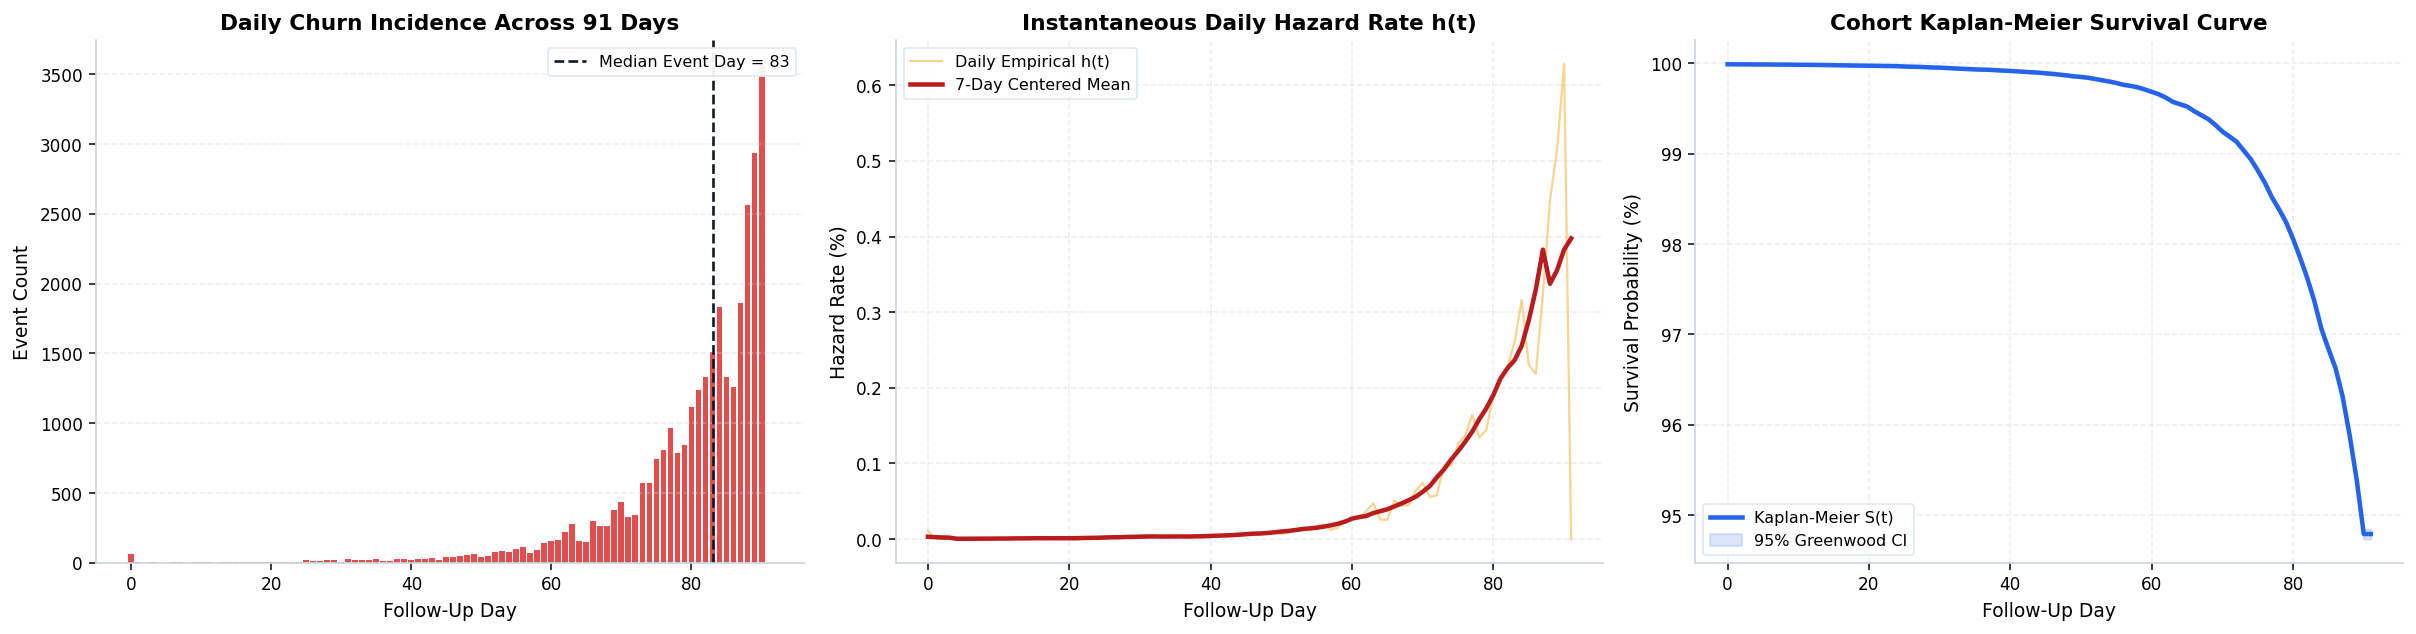

In [3]:
dur_all = train_labels["DURATION_DAYS"].to_numpy(dtype=np.int64)
ev_all = train_labels["EVENT_FLAG"].to_numpy(dtype=np.int64)
max_day = int(dur_all.max())

km_overall = kaplan_meier_table(dur_all, ev_all, max_day=max_day)
km_overall.to_csv(OUTPUT_DIR / "daily_hazard_table_91d.csv", index=False)

churned_days = dur_all[ev_all == 1]
peak_row = km_overall.loc[km_overall["events"].idxmax()]

timing_overview_df = pd.DataFrame([{
    "Total Accounts": len(dur_all),
    "Churned": int(len(churned_days)),
    "Censored": int((ev_all == 0).sum()),
    "Event Rate (%)": float(ev_all.mean() * 100.0),
    "P25 / Median / P75 Day": f"{np.percentile(churned_days, 25):.0f} / {np.median(churned_days):.0f} / {np.percentile(churned_days, 75):.0f}",
    "Mean Churn Day": float(churned_days.mean()),
    "Peak Churn Day": f"Day {int(peak_row['day'])} ({int(peak_row['events']):,} events, {peak_row['hazard_pct']:.4f}%)",
}])
display_table(
    timing_overview_df,
    title="Overall 91-Day Cohort Survival Summary",
    fmt={"Total Accounts": "{:,}", "Churned": "{:,}", "Censored": "{:,}", "Event Rate (%)": "{:.2f}", "Mean Churn Day": "{:.2f}"}
)

window_rows = []
for lo, hi, label in [(0, 30, "Early Horizon (0-30d)"), (31, 60, "Mid Horizon (31-60d)"), (61, max_day, f"Late Horizon (61-{max_day}d)")]:
    sub = km_overall[(km_overall["day"] >= lo) & (km_overall["day"] <= hi)]
    tot_ev = int(sub["events"].sum())
    window_rows.append({
        "Observation Window": label,
        "Churn Events": tot_ev,
        "Share of Total Churns (%)": 100.0 * tot_ev / max(1, len(churned_days)),
        "Mean Daily Hazard (%)": float(sub["hazard_pct"].mean()),
        "Period-End KM Survival (%)": float(sub["survival"].iloc[-1] * 100.0),
    })
window_hazard_df = pd.DataFrame(window_rows)
display_table(
    window_hazard_df,
    title="Discrete Horizon Churn Concentration and Empirical Hazard",
    fmt={"Churn Events": "{:,}", "Share of Total Churns (%)": "{:.2f}", "Mean Daily Hazard (%)": "{:.4f}", "Period-End KM Survival (%)": "{:.2f}"}
)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].bar(km_overall["day"], km_overall["events"], color="#dc2626", alpha=0.82, width=0.85)
axes[0].axvline(np.median(churned_days), color="#0f172a", linestyle="--", lw=1.4, label=f"Median Event Day = {np.median(churned_days):.0f}")
axes[0].set_title("Daily Churn Incidence Across 91 Days")
axes[0].set_xlabel("Follow-Up Day")
axes[0].set_ylabel("Event Count")
axes[0].legend(loc="upper right")
_style_ax(axes[0], "y")

axes[1].plot(km_overall["day"], km_overall["hazard_pct"], color="#f59e0b", alpha=0.45, lw=1.2, label="Daily Empirical h(t)")
axes[1].plot(km_overall["day"], km_overall["hazard_7d_smooth_pct"], color="#b91c1c", lw=2.4, label="7-Day Centered Mean")
axes[1].set_title("Instantaneous Daily Hazard Rate h(t)")
axes[1].set_xlabel("Follow-Up Day")
axes[1].set_ylabel("Hazard Rate (%)")
axes[1].legend(loc="upper left")
_style_ax(axes[1], "both")

axes[2].plot(km_overall["day"], km_overall["survival"] * 100.0, color="#2563eb", lw=2.4, label="Kaplan-Meier S(t)")
axes[2].fill_between(km_overall["day"], km_overall["ci_lower"] * 100.0, km_overall["ci_upper"] * 100.0, color="#2563eb", alpha=0.16, label="95% Greenwood CI")
axes[2].set_title("Cohort Kaplan-Meier Survival Curve")
axes[2].set_xlabel("Follow-Up Day")
axes[2].set_ylabel("Survival Probability (%)")
axes[2].legend(loc="lower left")
_style_ax(axes[2], "both")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "churn_timing_and_hazard_91d.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Non-Parametric Cohort Stratification: Tenure, Gender, and Geography

We evaluate heterogeneity across demographic and tenure segments derived from `kyc` records relative to `2024-03-31`. Accounts are partitioned by median tenure into newer and older cohorts, compared statistically using the two-sample log-rank test (`chi2`, p-value), and summarized via 30-, 60-, and 90-day Kaplan-Meier survival probabilities across `GENDER`, `REGION`, and `ACCOUNT_TYPE`.

Comparison,Newer Cohort N,Older Cohort N,Chi-Square Statistic,Log-Rank p-value
Median Tenure Split (1434 days),"297,973","297,027",4.77,2.891e-02


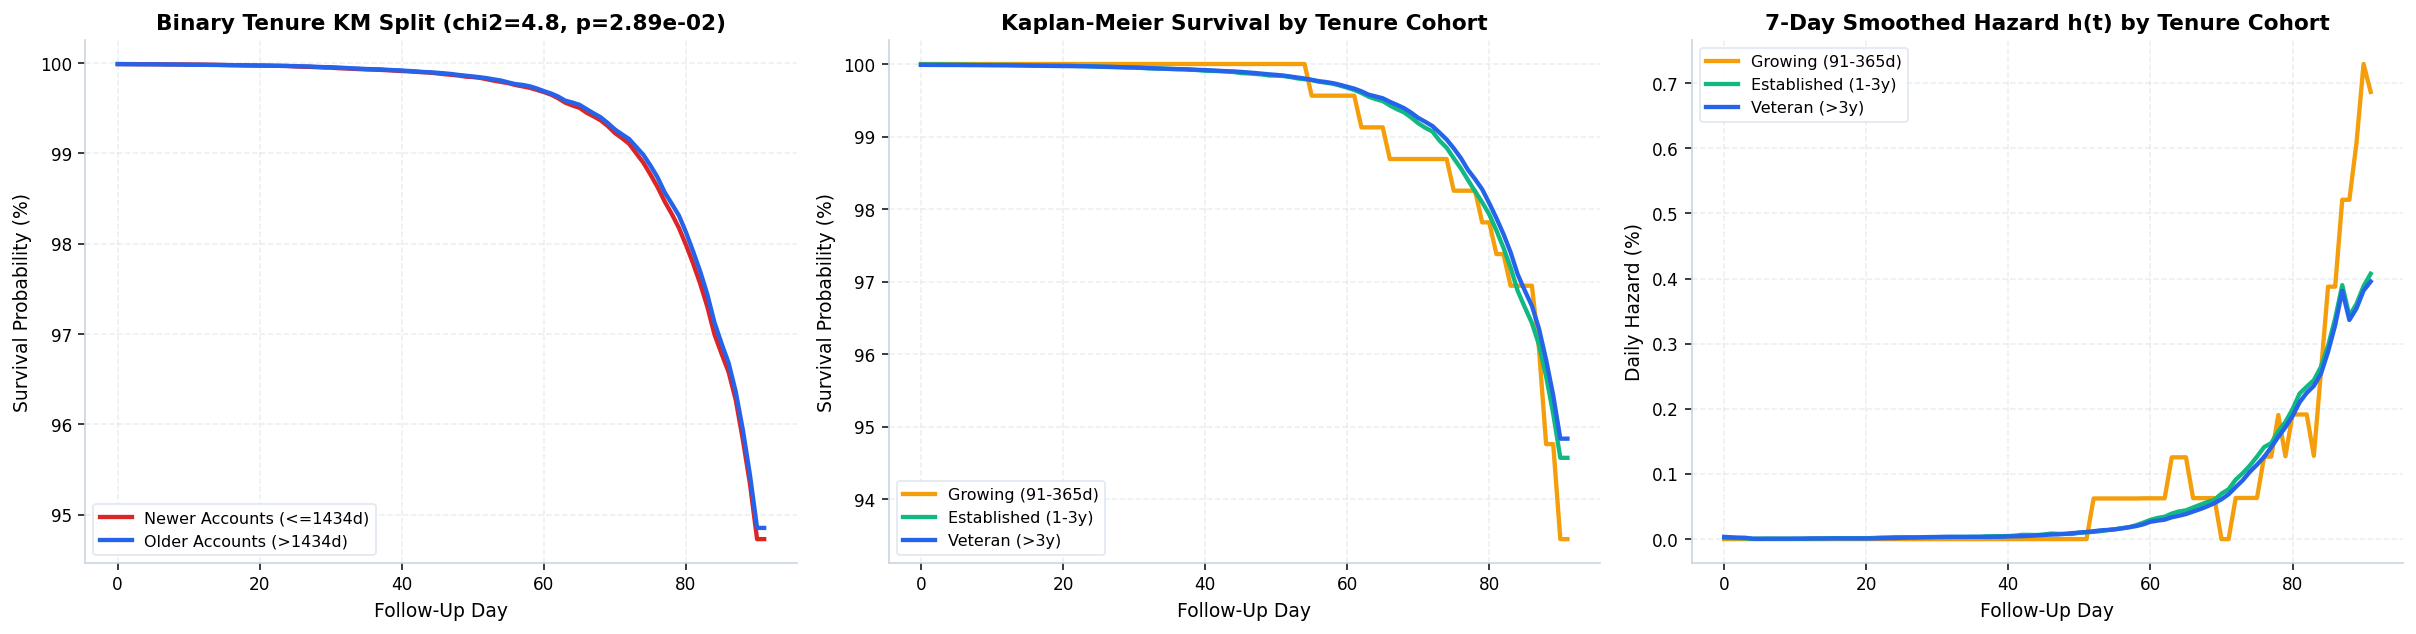

Segment Group,Cohort,Accounts,Churn Events,Churn Rate (%),Hazard / 1k Person-Days,KM 90d Survival (%)
Tenure,Growing (91-365d),229,15,6.55,0.725,93.45
Tenure,Established (1-3y),"97,303","5,283",5.43,0.601,94.57
Tenure,Veteran (>3y),"497,468","25,696",5.17,0.571,94.83
Region,Barishal,"41,459","2,181",5.26,0.582,94.74
Region,Chattogram,"106,808","5,506",5.16,0.570,94.84
Region,Dhaka,"208,593","11,006",5.28,0.584,94.72
Region,Khulna,"53,230","2,749",5.16,0.571,94.84
Region,Mymensingh,"35,603","1,827",5.13,0.568,94.87
Region,Rajshahi,"59,724","3,112",5.21,0.576,94.79
Region,Rangpur,"30,052","1,513",5.03,0.557,94.97


14696

In [4]:
kyc_pd = (
    kyc.with_columns([
        (pl.lit(OBS_DATE) - pl.col("ACCOUNT_OPEN_DATE").cast(pl.Date)).dt.total_days().cast(pl.Int32).alias("account_tenure_days")
    ])
    .select(["ACCOUNT_ID", "account_tenure_days", "GENDER", "REGION", "ACCOUNT_TYPE"])
    .to_pandas()
)
surv_df = train_labels.merge(kyc_pd, on="ACCOUNT_ID", how="left")
surv_df["account_tenure_days"] = surv_df["account_tenure_days"].fillna(surv_df["account_tenure_days"].median())

bins = [-10**9, 90, 365, 1095, 10**9]
labels_4 = ["New (<=90d)", "Growing (91-365d)", "Established (1-3y)", "Veteran (>3y)"]
surv_df["TENURE_SEGMENT"] = pd.cut(surv_df["account_tenure_days"], bins=bins, labels=labels_4)

split_days = int(surv_df["account_tenure_days"].median())
g_new = f"Newer Accounts (<={split_days}d)"
g_old = f"Older Accounts (>{split_days}d)"
surv_df["CUSTOMER_AGE_GROUP"] = np.where(surv_df["account_tenure_days"] <= split_days, g_new, g_old)
sub_new = surv_df[surv_df["CUSTOMER_AGE_GROUP"] == g_new]
sub_old = surv_df[surv_df["CUSTOMER_AGE_GROUP"] == g_old]

km_new = kaplan_meier_table(sub_new["DURATION_DAYS"].values, sub_new["EVENT_FLAG"].values, max_day=max_day)
km_old = kaplan_meier_table(sub_old["DURATION_DAYS"].values, sub_old["EVENT_FLAG"].values, max_day=max_day)
chi2_no, pval_no = logrank_test_2sample(
    sub_new["DURATION_DAYS"].values, sub_new["EVENT_FLAG"].values,
    sub_old["DURATION_DAYS"].values, sub_old["EVENT_FLAG"].values
)

logrank_df = pd.DataFrame([{
    "Comparison": f"Median Tenure Split ({split_days} days)",
    "Newer Cohort N": len(sub_new),
    "Older Cohort N": len(sub_old),
    "Chi-Square Statistic": chi2_no,
    "Log-Rank p-value": f"{pval_no:.3e}",
}])
display_table(logrank_df, title="Two-Sample Log-Rank Test Across Tenure Cohorts", fmt={"Newer Cohort N": "{:,}", "Older Cohort N": "{:,}", "Chi-Square Statistic": "{:.2f}"})

km_tenure, seg_rows = {}, []
for seg in labels_4:
    sub = surv_df[surv_df["TENURE_SEGMENT"] == seg]
    if len(sub) < 10:
        continue
    kt = kaplan_meier_table(sub["DURATION_DAYS"].values, sub["EVENT_FLAG"].values, max_day=max_day)
    km_tenure[seg] = kt
    seg_rows.append({
        "Segment Group": "Tenure", "Cohort": seg, "Accounts": len(sub), "Churn Events": int(sub["EVENT_FLAG"].sum()),
        "Churn Rate (%)": float(sub["EVENT_FLAG"].mean() * 100.0),
        "Hazard / 1k Person-Days": 1000.0 * float(sub["EVENT_FLAG"].sum()) / max(1.0, float(sub["DURATION_DAYS"].sum())),
        "KM 90d Survival (%)": float(kt.loc[kt["day"] == min(90, max_day), "survival"].values[0] * 100.0),
    })

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for lbl, kt, col in [(g_new, km_new, "#dc2626"), (g_old, km_old, "#2563eb")]:
    axes[0].plot(kt["day"], kt["survival"] * 100.0, color=col, lw=2.3, label=lbl)
axes[0].set_title(f"Binary Tenure KM Split (chi2={chi2_no:.1f}, p={pval_no:.2e})")
axes[0].set_xlabel("Follow-Up Day")
axes[0].set_ylabel("Survival Probability (%)")
axes[0].legend(loc="lower left")
_style_ax(axes[0], "both")

palette_4 = ["#dc2626", "#f59e0b", "#10b981", "#2563eb"]
for seg, col in zip(labels_4, palette_4):
    if seg in km_tenure:
        axes[1].plot(km_tenure[seg]["day"], km_tenure[seg]["survival"] * 100.0, color=col, lw=2.3, label=seg)
        axes[2].plot(km_tenure[seg]["day"], km_tenure[seg]["hazard_7d_smooth_pct"], color=col, lw=2.3, label=seg)
axes[1].set_title("Kaplan-Meier Survival by Tenure Cohort")
axes[1].set_xlabel("Follow-Up Day")
axes[1].set_ylabel("Survival Probability (%)")
axes[1].legend(loc="lower left")
_style_ax(axes[1], "both")

axes[2].set_title("7-Day Smoothed Hazard h(t) by Tenure Cohort")
axes[2].set_xlabel("Follow-Up Day")
axes[2].set_ylabel("Daily Hazard (%)")
axes[2].legend(loc="upper left")
_style_ax(axes[2], "both")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "km_new_vs_old_customers.png", bbox_inches="tight")
plt.show()
plt.close(fig)

for col_name, grp_label in [("REGION", "Region"), ("GENDER", "Gender")]:
    grp_df = surv_df.assign(**{col_name: surv_df[col_name].fillna("UNKNOWN").astype(str)})
    for val, sub in grp_df.groupby(col_name):
        if len(sub) < 50:
            continue
        kt = kaplan_meier_table(sub["DURATION_DAYS"].values, sub["EVENT_FLAG"].values, max_day=max_day)
        seg_rows.append({
            "Segment Group": grp_label, "Cohort": str(val), "Accounts": len(sub), "Churn Events": int(sub["EVENT_FLAG"].sum()),
            "Churn Rate (%)": float(sub["EVENT_FLAG"].mean() * 100.0),
            "Hazard / 1k Person-Days": 1000.0 * float(sub["EVENT_FLAG"].sum()) / max(1.0, float(sub["DURATION_DAYS"].sum())),
            "KM 90d Survival (%)": float(kt.loc[kt["day"] == min(90, max_day), "survival"].values[0] * 100.0),
        })
kyc_seg_summary = pd.DataFrame(seg_rows)
kyc_seg_summary.to_csv(OUTPUT_DIR / "kyc_segment_hazard_summary.csv", index=False)
display_table(
    kyc_seg_summary,
    title="Kaplan-Meier Survival and Hazard Summary Across KYC Cohorts",
    fmt={"Accounts": "{:,}", "Churn Events": "{:,}", "Churn Rate (%)": "{:.2f}", "Hazard / 1k Person-Days": "{:.3f}", "KM 90d Survival (%)": "{:.2f}"}
)
del surv_df, kyc_pd
gc.collect()

## 5. Longitudinal Transaction Feature Engineering via Consolidated `Polars` Scans

Naive event aggregation often requires repeated passes over multi-million-row transaction logs and omits incoming counterparty behavior. Instead, we consolidate outgoing (`SRC_ACCOUNT`) and non-self incoming (`DST_ACCOUNT`) aggregations into two single-pass lazy `Polars` pipelines:

* **Recency and Inter-Transaction Cadence:** Days since last overall activity, transaction-type-specific recency (`CashIn`, `CashOut`, `BillPay`, `MerchantPay`), and empirical inter-event gap dispersion (`gap_mean`, `gap_median`, `gap_std`).
* **Multi-Horizon Intensity and Momentum:** Cumulative counts, spend quantiles (`p25`, `median`, `p75`, `p90`), micro-transaction shares, monthly trajectory splits (`cnt_jan`, `cnt_feb`, `cnt_mar`), and weekly linear activity slopes (`txn_weekly_slope`).
* **Network Diversity and Peer-to-Peer Inflow:** Unique counterparty, biller, and merchant counts, counterparty concentration indices, and incoming transfer volumes excluding self-transfers.

In [5]:
t0 = time.time()

# Consolidate outgoing transaction aggregations in a single lazy scan bounded by OBS_DATE
txn_src = (
    txn_lf
    .filter(pl.col("SRC_ACCOUNT").is_in(ACTIVE_IDS))
    .with_columns([
        pl.col("TRX_DATETIME").str.slice(0, 10).str.to_date("%Y-%m-%d").alias("_TXN_DATE"),
        pl.col("TRX_DATETIME").str.slice(11, 2).cast(pl.Int8, strict=False).alias("_HR"),
        pl.col("TRX_AMT").cast(pl.Float32).alias("_AMT"),
    ])
    .filter(pl.col("_TXN_DATE") <= OBS_DATE)
)


def _win_mask(start_dt):
    return pl.col("_TXN_DATE") >= pl.lit(start_dt)


def _range_mask(start_dt, end_dt):
    return (pl.col("_TXN_DATE") >= pl.lit(start_dt)) & (pl.col("_TXN_DATE") < pl.lit(end_dt))


src_agg = (
    txn_src.group_by("SRC_ACCOUNT").agg([
        pl.len().alias("txn_count_all"),
        _win_mask(D_3).sum().cast(pl.Int32).alias("txn_count_3d"),
        _win_mask(D_7).sum().cast(pl.Int32).alias("txn_count_7d"),
        _win_mask(D_14).sum().cast(pl.Int32).alias("txn_count_14d"),
        _range_mask(D_28, D_14).sum().cast(pl.Int32).alias("txn_count_prev14d"),
        _win_mask(D_30).sum().cast(pl.Int32).alias("txn_count_30d"),
        _range_mask(D_60, D_30).sum().cast(pl.Int32).alias("cnt_30_60"),
        _range_mask(D_90, D_60).sum().cast(pl.Int32).alias("cnt_60_90"),
        _win_mask(D_60).sum().cast(pl.Int32).alias("txn_count_60d"),
        _win_mask(D_90).sum().cast(pl.Int32).alias("txn_count_90d"),

        (pl.col("_TXN_DATE").dt.month() == 1).sum().cast(pl.Int32).alias("cnt_jan"),
        (pl.col("_TXN_DATE").dt.month() == 2).sum().cast(pl.Int32).alias("cnt_feb"),
        (pl.col("_TXN_DATE").dt.month() == 3).sum().cast(pl.Int32).alias("cnt_mar"),

        pl.col("_TXN_DATE").n_unique().cast(pl.Int16).alias("active_days_all"),
        pl.col("_TXN_DATE").filter(_win_mask(D_7)).n_unique().cast(pl.Int16).alias("active_days_7d"),
        pl.col("_TXN_DATE").filter(_win_mask(D_14)).n_unique().cast(pl.Int16).alias("active_days_14d"),
        pl.col("_TXN_DATE").filter(_win_mask(D_30)).n_unique().cast(pl.Int16).alias("active_days_30d"),
        pl.col("_TXN_DATE").filter(_win_mask(D_60)).n_unique().cast(pl.Int16).alias("active_days_60d"),

        pl.col("_TXN_DATE").max().alias("_last_txn_date"),
        pl.col("_TXN_DATE").min().alias("_first_txn_date"),

        pl.col("_AMT").sum().alias("txn_amount_sum_all"),
        pl.col("_AMT").mean().alias("txn_amount_mean_all"),
        pl.col("_AMT").std().alias("txn_amount_std_all"),
        pl.col("_AMT").min().alias("txn_amount_min_all"),
        pl.col("_AMT").quantile(0.25).alias("txn_amount_p25_all"),
        pl.col("_AMT").median().alias("txn_amount_median_all"),
        pl.col("_AMT").quantile(0.75).alias("txn_amount_p75_all"),
        pl.col("_AMT").quantile(0.90).alias("txn_amount_p90_all"),
        pl.col("_AMT").max().alias("txn_amount_max_all"),
        pl.col("_AMT").filter(_win_mask(D_7)).sum().alias("txn_sum_7d"),
        pl.col("_AMT").filter(_win_mask(D_14)).sum().alias("txn_sum_14d"),
        pl.col("_AMT").filter(_win_mask(D_30)).sum().alias("txn_sum_30d"),
        pl.col("_AMT").filter(_win_mask(D_30)).mean().alias("txn_mean_30d"),
        pl.col("_AMT").filter(_win_mask(D_30)).std().alias("txn_std_30d"),
        (pl.col("_AMT") < 100.0).mean().alias("pct_micro_txn_lt100"),
        ((pl.col("_AMT") % 100.0) < 0.01).mean().alias("pct_round_100_txn"),

        pl.col("DST_ACCOUNT").n_unique().cast(pl.Int32).alias("n_unique_counterparties"),
        pl.col("DST_ACCOUNT").filter(pl.col("TRX_TYPE") == "MerchantPay").n_unique().cast(pl.Int32).alias("n_unique_merchants"),
        pl.col("DST_ACCOUNT").filter(pl.col("TRX_TYPE") == "BillPay").n_unique().cast(pl.Int32).alias("n_unique_billers"),
        pl.col("DST_ACCOUNT").filter(pl.col("TRX_TYPE") == "P2P").n_unique().cast(pl.Int32).alias("n_unique_p2p_receivers"),

        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "CashIn").max().alias("_last_CashIn"),
        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "CashOut").max().alias("_last_CashOut"),
        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "BillPay").max().alias("_last_BillPay"),
        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "MerchantPay").max().alias("_last_MerchantPay"),
        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "P2P").max().alias("_last_P2P"),

        pl.col("_HR").mean().alias("hour_mean"),
        pl.col("_HR").std().alias("hour_std"),
        (pl.col("_TXN_DATE").dt.weekday() >= 6).mean().alias("weekend_ratio"),
        ((pl.col("_HR") >= 22) | (pl.col("_HR") <= 5)).mean().alias("night_ratio"),
    ])
    .with_columns([
        (pl.lit(OBS_DATE) - pl.col("_last_txn_date")).dt.total_days().cast(pl.Int16).alias("recency_days"),
        (pl.lit(OBS_DATE) - pl.col("_first_txn_date")).dt.total_days().cast(pl.Int16).alias("first_txn_age_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_CashIn")).dt.total_days().cast(pl.Int16).alias("recency_CashIn_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_CashOut")).dt.total_days().cast(pl.Int16).alias("recency_CashOut_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_BillPay")).dt.total_days().cast(pl.Int16).alias("recency_BillPay_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_MerchantPay")).dt.total_days().cast(pl.Int16).alias("recency_MerchantPay_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_P2P")).dt.total_days().cast(pl.Int16).alias("recency_P2P_days"),
    ])
    .drop(["_last_txn_date", "_first_txn_date", "_last_CashIn", "_last_CashOut", "_last_BillPay", "_last_MerchantPay", "_last_P2P"])
    .collect()
    .rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
)

# Outgoing transaction-type pivot and Shannon diversity entropy
txn_type_raw = (
    txn_src.group_by(["SRC_ACCOUNT", "TRX_TYPE"])
    .agg([pl.len().alias("type_count"), pl.col("_AMT").sum().alias("type_sum")])
    .collect()
)
txn_type_pivot = (
    txn_type_raw.pivot(on="TRX_TYPE", index="SRC_ACCOUNT", values=["type_count", "type_sum"], aggregate_function="sum")
    .fill_null(0).rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
)
txn_type_pivot.columns = [c.replace('"', "").replace("{", "").replace("}", "").replace(",", "_").replace(" ", "_") for c in txn_type_pivot.columns]

_type_totals = txn_type_raw.group_by("SRC_ACCOUNT").agg(pl.col("type_count").sum().alias("total_cnt"))
entropy_feat = (
    txn_type_raw.join(_type_totals, on="SRC_ACCOUNT")
    .with_columns((pl.col("type_count") / pl.col("total_cnt")).alias("p"))
    .with_columns((-(pl.col("p") * pl.col("p").log())).alias("plogp"))
    .group_by("SRC_ACCOUNT").agg(pl.col("plogp").sum().alias("txn_type_entropy"))
    .rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
)


def _weekly_slope(lf_or_df, date_col, value_expr, value_name, id_col, slope_name):
    """Compute closed-form ordinary least squares slope across weekly aggregated counts/volumes."""
    weekly = (
        lf_or_df
        .with_columns(((pl.col(date_col) - pl.lit(date(2024, 1, 1))).dt.total_days() // 7).alias("week_idx"))
        .group_by([id_col, "week_idx"]).agg(value_expr.alias(value_name))
    )
    if hasattr(weekly, "collect"):
        weekly = weekly.collect()
    return (
        weekly.group_by(id_col).agg([
            pl.len().alias("n_w"),
            pl.col("week_idx").sum().alias("sx"),
            pl.col(value_name).sum().alias("sy"),
            (pl.col("week_idx") * pl.col(value_name)).sum().alias("sxy"),
            (pl.col("week_idx") ** 2).sum().alias("sx2"),
        ]).with_columns([
            ((pl.col("n_w") * pl.col("sxy") - pl.col("sx") * pl.col("sy")) /
             (pl.col("n_w") * pl.col("sx2") - pl.col("sx") ** 2 + 1e-9)).alias(slope_name)
        ]).select([id_col, slope_name])
    )


txn_count_slope = _weekly_slope(txn_src, "_TXN_DATE", pl.len(), "wcnt", "SRC_ACCOUNT", "txn_weekly_slope").rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
txn_amt_slope = _weekly_slope(txn_src, "_TXN_DATE", pl.col("_AMT").sum(), "wamt", "SRC_ACCOUNT", "txn_amount_weekly_slope").rename({"SRC_ACCOUNT": "ACCOUNT_ID"})

gap_feats = (
    txn_src.select(["SRC_ACCOUNT", "_TXN_DATE"]).unique().sort(["SRC_ACCOUNT", "_TXN_DATE"])
    .with_columns(pl.col("_TXN_DATE").diff().over("SRC_ACCOUNT").dt.total_days().alias("day_gap"))
    .group_by("SRC_ACCOUNT").agg([
        pl.col("day_gap").mean().alias("gap_mean"),
        pl.col("day_gap").median().alias("gap_median"),
        pl.col("day_gap").max().alias("gap_max"),
        pl.col("day_gap").std().alias("gap_std"),
        pl.col("day_gap").last().alias("gap_last"),
    ])
    .collect().rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
)

# Consolidate incoming counterparty and strictly non-self P2P inflows
dst_agg = (
    txn_lf
    .filter(pl.col("DST_ACCOUNT").is_in(ACTIVE_IDS))
    .with_columns([
        pl.col("TRX_DATETIME").str.slice(0, 10).str.to_date("%Y-%m-%d").alias("_TXN_DATE"),
        pl.col("TRX_AMT").cast(pl.Float32).alias("_AMT"),
        (pl.col("SRC_ACCOUNT") != pl.col("DST_ACCOUNT")).alias("_nonself"),
    ])
    .filter(pl.col("_TXN_DATE") <= OBS_DATE)
    .group_by("DST_ACCOUNT").agg([
        pl.len().alias("inflow_count"),
        pl.col("_AMT").sum().alias("total_inflow"),
        pl.col("_AMT").filter(_win_mask(D_30)).sum().alias("total_inflow_30d"),
        pl.col("_nonself").sum().cast(pl.Int32).alias("p2p_in_cnt"),
        pl.col("_AMT").filter(pl.col("_nonself")).sum().alias("p2p_in_sum"),
        (pl.col("_nonself") & _win_mask(D_14)).sum().cast(pl.Int32).alias("p2p_in_cnt_14d"),
        (pl.col("_nonself") & _win_mask(D_30)).sum().cast(pl.Int32).alias("p2p_in_cnt_30d"),
        pl.col("SRC_ACCOUNT").filter(pl.col("_nonself")).n_unique().cast(pl.Int32).alias("n_unique_p2p_senders"),
        pl.col("_TXN_DATE").filter(pl.col("_nonself")).max().alias("_last_p2p_in"),
    ])
    .with_columns([
        (pl.lit(OBS_DATE) - pl.col("_last_p2p_in")).dt.total_days().cast(pl.Int16).alias("p2p_in_recency_days"),
    ])
    .drop("_last_p2p_in")
    .collect().rename({"DST_ACCOUNT": "ACCOUNT_ID"})
)

txn_pass_summary_df = pd.DataFrame([
    {"Feature Block": "Outgoing Multi-Scale Velocity (SRC)", "Accounts": src_agg.height, "Feature Count": src_agg.width - 1},
    {"Feature Block": "Transaction-Type Pivot & Entropy", "Accounts": txn_type_pivot.height, "Feature Count": (txn_type_pivot.width - 1) + (entropy_feat.width - 1)},
    {"Feature Block": "Weekly OLS Trend & Gap Dispersion", "Accounts": gap_feats.height, "Feature Count": (gap_feats.width - 1) + 2},
    {"Feature Block": "Non-Self P2P Inflow Dynamics (DST)", "Accounts": dst_agg.height, "Feature Count": dst_agg.width - 1},
])
display_table(
    txn_pass_summary_df,
    title=f"Longitudinal Transaction Feature Engineering Summary ({time.time() - t0:.1f}s)",
    fmt={"Accounts": "{:,}", "Feature Count": "{:,}"}
)

Feature Block,Accounts,Feature Count
Outgoing Multi-Scale Velocity (SRC),"849,690",49
Transaction-Type Pivot & Entropy,"849,690",11
Weekly OLS Trend & Gap Dispersion,"849,690",7
Non-Self P2P Inflow Dynamics (DST),"841,776",9


## 6. Daily Balance Dynamics, Behavioral Ratios, and Feature Matrix Assembly

We process daily end-of-day balance trajectories (`dayend_balance`) in a single sorted `Polars` pass to capture liquidity stress and capital flight signals, including zero-balance frequency, drawdowns from peak holdings, consecutive flat-balance streaks, balance half-period slope acceleration (`slope_h1`, `slope_h2`), and late-window versus baseline shifts. Transaction, balance, and encoded `kyc` tables are joined cleanly onto `all_ids_needed` and augmented with cross-domain behavioral ratios to construct the candidate feature repository (`master`).

Behavioral Domain,Feature Count
"Outgoing Transactions, Entropy & Velocity",67
Non-Self P2P Inflow Dynamics,9
Daily Balance Physics & Drawdown Slopes,41
KYC Cohort & Demographic Encodings,7
Cross-Domain Ratios & Region Relative Norms,37
Total Assembled Feature Columns (excl. ID),161


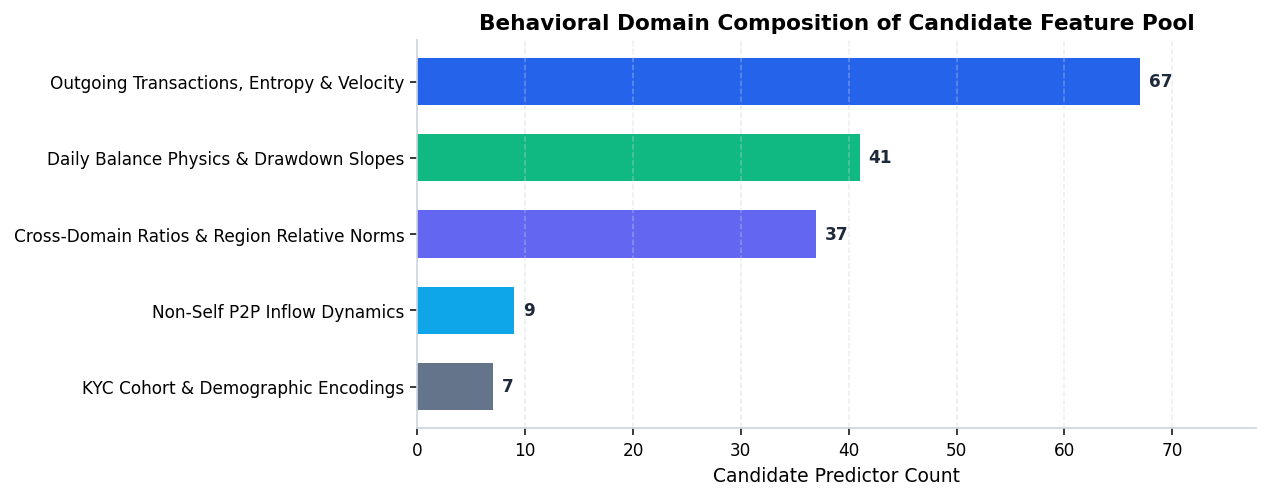

In [6]:
t1 = time.time()

# Sort longitudinal balance records once per account to compute exact day-over-day differences and zero-streak regimes
bal_df = (
    bal_lf
    .filter(pl.col("ACCOUNT_ID").is_in(ACTIVE_IDS))
    .with_columns([
        pl.col("DATE").str.to_date("%Y-%m-%d").alias("_BAL_DATE"),
        pl.col("AVAILABLE_BALANCE").cast(pl.Float32).alias("_BAL"),
    ])
    .filter(pl.col("_BAL_DATE") <= OBS_DATE)
    .select(["ACCOUNT_ID", "_BAL_DATE", "_BAL"])
    .sort(["ACCOUNT_ID", "_BAL_DATE"])
    .collect()
)

# Segment contiguous zero-balance regimes using cumulative regime-change identifiers
bal_df = bal_df.with_columns([
    pl.col("_BAL").diff().over("ACCOUNT_ID").alias("_DBAL"),
    (pl.col("_BAL") == 0.0).alias("_IS_ZERO"),
])
bal_df = bal_df.with_columns([
    (pl.col("_IS_ZERO") != pl.col("_IS_ZERO").shift(1)).fill_null(True).over("ACCOUNT_ID").alias("_ZCHG"),
])
bal_df = bal_df.with_columns([
    pl.col("_ZCHG").cast(pl.Int32).cum_sum().over("ACCOUNT_ID").alias("_ZSTREAK_ID"),
])

zero_streak = (
    bal_df.filter(pl.col("_IS_ZERO"))
    .group_by(["ACCOUNT_ID", "_ZSTREAK_ID"]).agg(pl.len().alias("_slen"))
    .group_by("ACCOUNT_ID").agg(pl.col("_slen").max().cast(pl.Int16).alias("bal_zero_streak_max"))
)

bal_feats = (
    bal_df.group_by("ACCOUNT_ID").agg([
        pl.len().cast(pl.Int16).alias("n_balance_records"),
        pl.col("_BAL").mean().alias("bal_mean"),
        pl.col("_BAL").std().alias("bal_std"),
        pl.col("_BAL").min().alias("bal_min"),
        pl.col("_BAL").quantile(0.10).alias("bal_p10"),
        pl.col("_BAL").median().alias("bal_median"),
        pl.col("_BAL").quantile(0.90).alias("bal_p90"),
        pl.col("_BAL").max().alias("bal_max"),
        pl.col("_BAL").first().alias("bal_first"),
        pl.col("_BAL").last().alias("bal_last"),

        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_7)).mean().alias("bal_mean_7d"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_14)).mean().alias("bal_mean_14d"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_30)).mean().alias("bal_mean_30d"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_30)).std().alias("bal_std_30d"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_30)).min().alias("bal_min_30d"),
        pl.col("_BAL").filter((pl.col("_BAL_DATE") >= pl.lit(date(2024, 1, 1))) & (pl.col("_BAL_DATE") < pl.lit(date(2024, 2, 1)))).mean().alias("bal_mean_jan"),
        pl.col("_BAL").filter((pl.col("_BAL_DATE") >= pl.lit(date(2024, 2, 1))) & (pl.col("_BAL_DATE") < pl.lit(date(2024, 3, 1)))).mean().alias("bal_mean_feb"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(date(2024, 3, 1))).mean().alias("bal_mean_mar"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(date(2024, 3, 1))).std().alias("bal_std_mar"),

        pl.col("_IS_ZERO").sum().cast(pl.Int16).alias("zero_bal_days"),
        pl.col("_IS_ZERO").mean().alias("zero_bal_ratio"),
        (pl.col("_BAL") < 10.0).sum().cast(pl.Int16).alias("bal_lt10_days"),
        (pl.col("_DBAL").abs() < 1e-4).sum().cast(pl.Int16).alias("bal_flat_days"),
        (pl.col("_DBAL").abs() < 1.0).sum().cast(pl.Int16).alias("bal_near_flat_days"),
        (pl.col("_DBAL") < -50.0).sum().cast(pl.Int16).alias("bal_neg_jump_days"),
        (pl.col("_DBAL") > 50.0).sum().cast(pl.Int16).alias("bal_pos_jump_days"),
        ((pl.col("_DBAL") < -50.0) & (pl.col("_BAL_DATE") >= pl.lit(D_30))).sum().cast(pl.Int16).alias("bal_neg_jump_30d"),
        ((pl.col("_DBAL") > 50.0) & (pl.col("_BAL_DATE") >= pl.lit(D_30))).sum().cast(pl.Int16).alias("bal_pos_jump_30d"),
        pl.col("_DBAL").min().alias("bal_max_single_drop"),
        pl.col("_DBAL").max().alias("bal_max_single_spike"),
        pl.col("_BAL_DATE").filter(pl.col("_DBAL").abs() >= 1.0).max().alias("_last_bal_move_dt"),
    ])
    .with_columns([
        (pl.lit(OBS_DATE) - pl.col("_last_bal_move_dt")).dt.total_days().cast(pl.Int16).alias("days_since_last_bal_move"),
        ((pl.col("bal_last") - pl.col("bal_first")) / (pl.col("bal_first").abs() + 1.0)).alias("bal_trend"),
        (pl.col("bal_std") / (pl.col("bal_mean").abs() + 1.0)).alias("bal_cv"),
        (pl.col("bal_last") / (pl.col("bal_max") + 1.0)).alias("bal_drain_ratio"),
        (pl.col("bal_max") - pl.col("bal_last")).alias("bal_drawdown_abs"),
        (pl.col("bal_mean_14d") / (pl.col("bal_mean_jan") + 1.0)).alias("bal_14d_vs_jan_ratio"),
        (pl.col("bal_mean_mar") / (pl.col("bal_mean_jan") + 1.0)).alias("bal_mar_vs_jan_ratio"),
    ])
    .drop("_last_bal_move_dt")
)

bal_weekly_raw = (
    bal_df
    .with_columns(((pl.col("_BAL_DATE") - pl.lit(date(2024, 1, 1))).dt.total_days() // 7).alias("week_idx"))
    .group_by(["ACCOUNT_ID", "week_idx"]).agg(pl.col("_BAL").mean().alias("wbal"))
)
bal_slope = (
    bal_weekly_raw.group_by("ACCOUNT_ID").agg([
        pl.len().alias("n_w"), pl.col("week_idx").sum().alias("sx"), pl.col("wbal").sum().alias("sy"),
        (pl.col("week_idx") * pl.col("wbal")).sum().alias("sxy"), (pl.col("week_idx") ** 2).sum().alias("sx2"),
    ]).with_columns([
        ((pl.col("n_w") * pl.col("sxy") - pl.col("sx") * pl.col("sy")) /
         (pl.col("n_w") * pl.col("sx2") - pl.col("sx") ** 2 + 1e-9)).alias("balance_weekly_slope")
    ]).select(["ACCOUNT_ID", "balance_weekly_slope"])
)

_mid = int(bal_weekly_raw["week_idx"].max() // 2) if bal_weekly_raw.height > 0 else 6


def _half_slope(df, lo, hi, suffix):
    """Estimate sub-period linear balance trend to capture second-order balance acceleration."""
    sub = df.filter((pl.col("week_idx") >= lo) & (pl.col("week_idx") < hi))
    return (
        sub.group_by("ACCOUNT_ID").agg([
            pl.len().alias(f"n_{suffix}"), pl.col("week_idx").sum().alias(f"sx_{suffix}"),
            pl.col("wbal").sum().alias(f"sy_{suffix}"), (pl.col("week_idx") * pl.col("wbal")).sum().alias(f"sxy_{suffix}"),
            (pl.col("week_idx") ** 2).sum().alias(f"sx2_{suffix}"),
        ]).with_columns([
            ((pl.col(f"n_{suffix}") * pl.col(f"sxy_{suffix}") - pl.col(f"sx_{suffix}") * pl.col(f"sy_{suffix}")) /
             (pl.col(f"n_{suffix}") * pl.col(f"sx2_{suffix}") - pl.col(f"sx_{suffix}") ** 2 + 1e-9)).alias(f"slope_{suffix}")
        ]).select(["ACCOUNT_ID", f"slope_{suffix}"])
    )


slope_h1 = _half_slope(bal_weekly_raw, 0, _mid, "h1")
slope_h2 = _half_slope(bal_weekly_raw, _mid, 100, "h2")

del bal_df, bal_weekly_raw
gc.collect()


def encode_cat_col(df: pl.DataFrame, src_col: str, dst_col: str, dtype) -> pl.DataFrame:
    """Deterministically encode sorted categorical levels with -1 reserved for unseen nulls."""
    vals = sorted([x for x in df[src_col].unique().to_list() if x is not None])
    lkp = pl.DataFrame({src_col: vals, dst_col: list(range(len(vals)))}).with_columns(pl.col(dst_col).cast(dtype))
    return df.join(lkp, on=src_col, how="left").with_columns(pl.col(dst_col).fill_null(-1).cast(dtype))


kyc_feats = kyc.with_columns([
    (pl.lit(OBS_DATE) - pl.col("ACCOUNT_OPEN_DATE").cast(pl.Date)).dt.total_days().cast(pl.Int32).alias("account_tenure_days"),
    pl.col("ACCOUNT_OPEN_DATE").cast(pl.Date).dt.year().cast(pl.Int16).alias("open_year"),
    pl.col("ACCOUNT_OPEN_DATE").cast(pl.Date).dt.month().cast(pl.Int8).alias("open_month"),
    (pl.col("REGION").fill_null("UNK") + "_" + pl.col("GENDER").fill_null("UNK")).alias("_REG_GEN"),
])
kyc_feats = encode_cat_col(kyc_feats, "GENDER", "gender_enc", pl.Int8)
kyc_feats = encode_cat_col(kyc_feats, "REGION", "region_enc", pl.Int16)
kyc_feats = encode_cat_col(kyc_feats, "ACCOUNT_TYPE", "account_type_enc", pl.Int8)
kyc_feats = encode_cat_col(kyc_feats, "_REG_GEN", "region_gender_enc", pl.Int16)
kyc_final = kyc_feats.select([
    "ACCOUNT_ID", "account_tenure_days", "open_year", "open_month",
    "gender_enc", "region_enc", "account_type_enc", "region_gender_enc"
])


def safe_join(base_df: pl.DataFrame, feat_df: pl.DataFrame, on="ACCOUNT_ID", how="left") -> pl.DataFrame:
    """Left-join feature block while dropping pre-existing overlapping columns cleanly."""
    on_cols = [on] if isinstance(on, str) else list(on)
    overlap = [c for c in feat_df.columns if c in base_df.columns and c not in on_cols]
    if overlap:
        base_df = base_df.drop(overlap)
    return base_df.join(feat_df, on=on, how=how)


n_src_block = (src_agg.width - 1) + (txn_type_pivot.width - 1) + (entropy_feat.width - 1) + 2 + (gap_feats.width - 1)
n_dst_block = dst_agg.width - 1
n_bal_block = (bal_feats.width - 1) + (zero_streak.width - 1) + 3
n_kyc_block = kyc_final.width - 1

master = pl.DataFrame({"ACCOUNT_ID": all_ids_needed})
for f in (src_agg, txn_type_pivot, entropy_feat, txn_count_slope, txn_amt_slope,
          gap_feats, dst_agg, bal_feats, zero_streak, bal_slope, slope_h1, slope_h2, kyc_final):
    master = safe_join(master, f, on="ACCOUNT_ID")

del src_agg, txn_type_pivot, entropy_feat, txn_count_slope, txn_amt_slope, gap_feats, dst_agg, bal_feats, zero_streak, bal_slope, slope_h1, slope_h2, kyc_final
gc.collect()

# Impute unobserved recency and inter-transaction gaps to full study span (91d); remaining missing counts default to 0
for c in ["recency_days", "recency_CashIn_days", "recency_CashOut_days", "recency_BillPay_days",
          "recency_MerchantPay_days", "recency_P2P_days", "p2p_in_recency_days",
          "days_since_last_bal_move", "gap_mean", "gap_median", "gap_max", "gap_std", "gap_last"]:
    if c in master.columns:
        master = master.with_columns(pl.col(c).fill_null(91))

nc = master.null_count()
master = master.with_columns([pl.col(c).fill_null(0) for c in master.columns if nc[c][0] > 0])

has_ci = "type_count_CashIn" in master.columns
has_co = "type_count_CashOut" in master.columns
has_bp = "type_count_BillPay" in master.columns
has_mp = "type_count_MerchantPay" in master.columns

extra_exprs = [
    pl.min_horizontal(["recency_days", "p2p_in_recency_days"]).alias("combined_recency_days"),
    (pl.col("total_inflow") / (pl.col("txn_amount_sum_all") + 1.0)).alias("inflow_outflow_ratio"),
    (pl.col("total_inflow") - pl.col("txn_amount_sum_all")).alias("net_flow"),
    (pl.col("total_inflow_30d") / (pl.col("txn_sum_30d") + 1.0)).alias("inflow_outflow_ratio_30d"),
    (pl.col("p2p_in_cnt") - (pl.col("type_count_P2P") if "type_count_P2P" in master.columns else pl.lit(0))).alias("p2p_net_cnt"),
    (pl.col("p2p_in_sum") - (pl.col("type_sum_P2P") if "type_sum_P2P" in master.columns else pl.lit(0))).alias("p2p_net_amt"),
    (pl.col("n_unique_p2p_receivers") + pl.col("n_unique_p2p_senders")).alias("total_unique_p2p_peers"),
    (pl.col("txn_count_all") / (pl.col("n_unique_counterparties") + 1.0)).alias("counterparty_concentration"),
    (pl.col("txn_amount_p75_all") - pl.col("txn_amount_p25_all")).alias("txn_amount_iqr_all"),
    ((pl.col("txn_amount_mean_all") - pl.col("txn_amount_median_all")) / (pl.col("txn_amount_std_all") + 1.0)).alias("txn_amount_skew_proxy"),
    (pl.col("txn_count_30d") / (pl.col("txn_count_all") + 1.0)).alias("txn_pct_last30d"),
    (pl.col("txn_count_14d") / (pl.col("txn_count_all") + 1.0)).alias("txn_pct_last14d"),
    (pl.col("txn_count_7d") / (pl.col("txn_count_all") + 1.0)).alias("txn_pct_last7d"),
    (pl.col("txn_count_7d") / (pl.col("txn_count_30d") + 1.0)).alias("activity_drop_7v30"),
    (pl.col("txn_count_14d") / (pl.col("txn_count_prev14d") + 1.0)).alias("decay_14d_vs_prev14d"),
    (pl.col("txn_count_30d") / (pl.col("cnt_30_60") + 1.0)).alias("decay_30d_vs_mid30d"),
    (pl.col("txn_count_30d") / (pl.col("cnt_60_90") + 1.0)).alias("decline_recent_vs_old"),
    (pl.col("cnt_30_60") / (pl.col("cnt_60_90") + 1.0)).alias("decline_mid_vs_old"),
    (pl.col("txn_count_30d") - pl.col("cnt_60_90")).alias("decline_abs"),
    (pl.col("cnt_mar") / (pl.col("cnt_jan") + 1.0)).alias("mar_over_jan"),
    (pl.col("cnt_mar") / (pl.col("cnt_feb") + 1.0)).alias("mar_over_feb"),
    (pl.col("recency_days") / (pl.col("gap_mean") + 1.0)).alias("overdue_ratio"),
    ((pl.col("recency_days") - pl.col("gap_median")) / (pl.col("gap_std") + 1.0)).alias("gap_zscore"),
    (pl.col("slope_h2") - pl.col("slope_h1")).alias("balance_acceleration"),
    (pl.col("bal_mean") / (pl.col("txn_amount_mean_all").abs() + 1.0)).alias("balance_to_txn_ratio"),
    (pl.col("recency_days") / (pl.col("account_tenure_days") + 1.0)).alias("recency_to_tenure_ratio"),
    (pl.col("txn_amount_sum_all") / (pl.col("active_days_all") + 1.0)).alias("txn_amt_per_active_day"),
    (pl.col("txn_count_all") / (pl.col("active_days_all") + 1.0)).alias("txn_per_active_day"),
    (pl.col("bal_mean") - pl.col("bal_mean").median().over("region_enc")).alias("bal_diff_region_med"),
    (pl.col("txn_count_all") - pl.col("txn_count_all").median().over("region_enc")).alias("txn_diff_region_med"),
    (pl.col("n_unique_billers") / (pl.col("active_days_all") + 1.0)).alias("billers_per_active_day"),
    (pl.col("n_unique_merchants") / (pl.col("active_days_all") + 1.0)).alias("merchants_per_active_day"),
    (pl.col("txn_amount_p25_all") / (pl.col("txn_amount_median_all") + 1.0)).alias("amt_p25_to_median_ratio"),
    (pl.col("bal_p10") / (pl.col("bal_p90") + 1.0)).alias("bal_p10_to_p90_ratio"),
    (pl.col("cnt_mar") / ((pl.col("cnt_jan") + pl.col("cnt_feb")) * 0.5 + 1.0)).alias("txn_cnt_mar_vs_jan_feb_avg"),
]
if has_ci and has_co:
    extra_exprs.append((pl.col("type_count_CashIn") / (pl.col("type_count_CashOut") + 1.0)).alias("cashin_to_cashout_ratio"))
if has_bp and has_mp:
    extra_exprs.append(((pl.col("type_count_BillPay") + pl.col("type_count_MerchantPay")) / (pl.col("txn_count_all") + 1.0)).alias("utility_merchant_share"))

master = master.with_columns(extra_exprs)

domain_rows = [
    {"Behavioral Domain": "Outgoing Transactions, Entropy & Velocity", "Feature Count": n_src_block},
    {"Behavioral Domain": "Non-Self P2P Inflow Dynamics", "Feature Count": n_dst_block},
    {"Behavioral Domain": "Daily Balance Physics & Drawdown Slopes", "Feature Count": n_bal_block},
    {"Behavioral Domain": "KYC Cohort & Demographic Encodings", "Feature Count": n_kyc_block},
    {"Behavioral Domain": "Cross-Domain Ratios & Region Relative Norms", "Feature Count": len(extra_exprs)},
]
feature_inventory_df = pd.DataFrame(domain_rows + [{"Behavioral Domain": "Total Assembled Feature Columns (excl. ID)", "Feature Count": master.width - 1}])
display_table(
    feature_inventory_df,
    title=f"Master Feature Matrix Assembly ({master.height:,} accounts x {master.width - 1} predictors in {time.time() - t1:.1f}s)",
    fmt={"Feature Count": "{:,}"}
)

fig, ax = plt.subplots(figsize=(9.5, 3.8))
plot_dom = pd.DataFrame(domain_rows).sort_values("Feature Count", ascending=True)
colors_dom = ["#64748b", "#0ea5e9", "#6366f1", "#10b981", "#2563eb"]
bars = ax.barh(plot_dom["Behavioral Domain"], plot_dom["Feature Count"], color=colors_dom, height=0.62)
for b in bars:
    w = b.get_width()
    ax.text(w + 0.8, b.get_y() + b.get_height() / 2.0, f"{int(w)}", va="center", fontsize=9, fontweight="bold", color="#1e293b")
ax.set_xlim(0, plot_dom["Feature Count"].max() * 1.16)
ax.set_xlabel("Candidate Predictor Count")
ax.set_title("Behavioral Domain Composition of Candidate Feature Pool")
_style_ax(ax, "x")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_domain_composition.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. Behavioral Risk Validation: Activity, Zero-Balance Exposure, and Liquidity Decay

To verify domain validity prior to parametric and tree-based modeling, we partition accounts into interpretable tiers based on cumulative transaction count, zero-balance day exposure, and activity recency. Comparing empirical event rates and 30/60/90-day Kaplan-Meier survival estimates confirms monotonic risk separation across behavioral regimes.

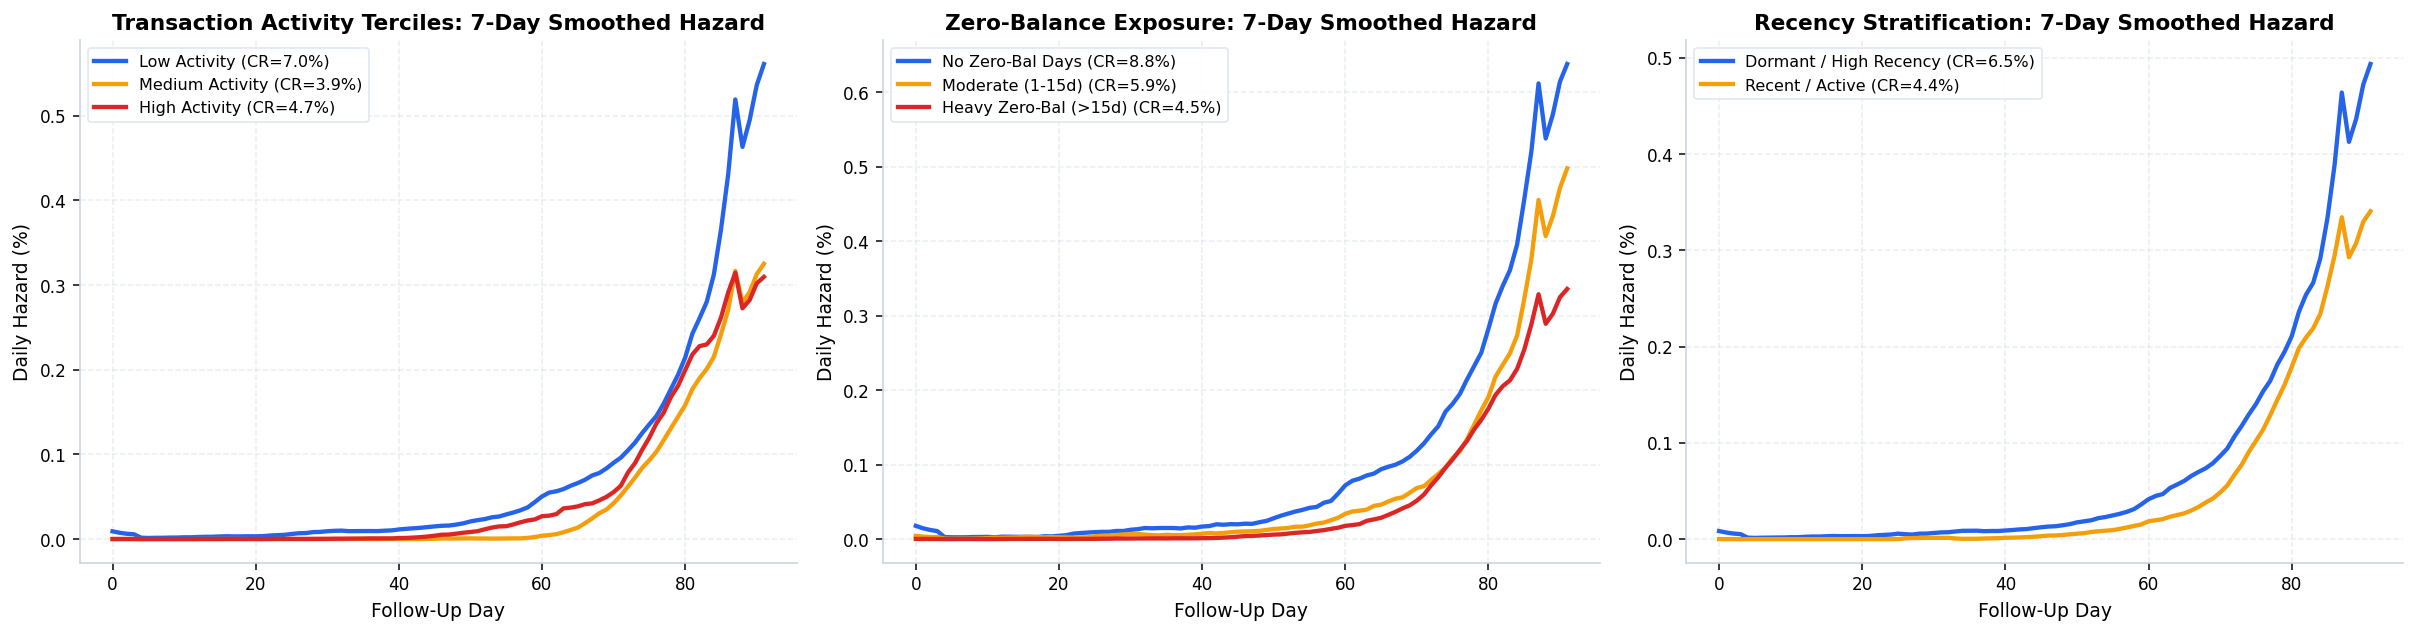

Behavioral Dimension,Tier,Accounts,Churn Events,Churn Rate (%),Hazard / 1k Person-Days,KM 90d Survival (%)
Transaction Activity Terciles,Low Activity,"198,333","13,902",7.01,0.778,92.99
Transaction Activity Terciles,Medium Activity,"198,333","7,778",3.92,0.432,96.08
Transaction Activity Terciles,High Activity,"198,334","9,314",4.70,0.519,95.30
Zero-Balance Exposure,No Zero-Bal Days,"72,500","6,382",8.80,0.981,91.20
Zero-Balance Exposure,Moderate (1-15d),"96,464","5,650",5.86,0.648,94.14
Zero-Balance Exposure,Heavy Zero-Bal (>15d),"426,036","18,962",4.45,0.491,95.55
Recency Stratification,Dormant / High Recency,"224,064","14,530",6.48,0.719,93.52
Recency Stratification,Recent / Active,"370,936","16,464",4.44,0.490,95.56


In [7]:
master_tf = master.to_pandas()
del master
gc.collect()

trn_ids = SAMPLE_TRAIN_IDS if USE_SAMPLE else set(all_train_ids)
train = train_labels[train_labels["ACCOUNT_ID"].isin(trn_ids)].merge(master_tf, on="ACCOUNT_ID", how="left")
test = test_df[["ACCOUNT_ID"]].merge(master_tf, on="ACCOUNT_ID", how="left")
del master_tf
gc.collect()

train["_act_tier"] = pd.qcut(train["txn_count_all"].rank(method="first"), q=3, labels=["Low Activity", "Medium Activity", "High Activity"])
train["_zero_tier"] = pd.cut(train["zero_bal_days"], bins=[-1, 0, 15, 100], labels=["No Zero-Bal Days", "Moderate (1-15d)", "Heavy Zero-Bal (>15d)"])
train["_rec_tier"] = np.where(train["recency_days"] > train["recency_days"].median(), "Dormant / High Recency", "Recent / Active")

behav_rows = []
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
seg_palette = ["#2563eb", "#f59e0b", "#dc2626"]
for col_seg, title_seg, ax in [
    ("_act_tier", "Transaction Activity Terciles", axes[0]),
    ("_zero_tier", "Zero-Balance Exposure", axes[1]),
    ("_rec_tier", "Recency Stratification", axes[2]),
]:
    for idx_v, (val, sub) in enumerate(train.groupby(col_seg, observed=True)):
        kt = kaplan_meier_table(sub["DURATION_DAYS"].values, sub["EVENT_FLAG"].values, max_day=max_day)
        col = seg_palette[idx_v % len(seg_palette)]
        ax.plot(kt["day"], kt["hazard_7d_smooth_pct"], color=col, lw=2.3, label=f"{val} (CR={sub['EVENT_FLAG'].mean() * 100:.1f}%)")
        behav_rows.append({
            "Behavioral Dimension": title_seg, "Tier": str(val), "Accounts": len(sub), "Churn Events": int(sub["EVENT_FLAG"].sum()),
            "Churn Rate (%)": float(sub["EVENT_FLAG"].mean() * 100.0),
            "Hazard / 1k Person-Days": 1000.0 * float(sub["EVENT_FLAG"].sum()) / max(1.0, float(sub["DURATION_DAYS"].sum())),
            "KM 90d Survival (%)": float(kt.loc[kt["day"] == min(90, max_day), "survival"].values[0] * 100.0),
        })
    ax.set_title(f"{title_seg}: 7-Day Smoothed Hazard")
    ax.set_xlabel("Follow-Up Day")
    ax.set_ylabel("Daily Hazard (%)")
    ax.legend(loc="upper left")
    _style_ax(ax, "both")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "behavioral_segment_hazards.png", bbox_inches="tight")
plt.show()
plt.close(fig)

behav_summary = pd.DataFrame(behav_rows)
behav_summary.to_csv(OUTPUT_DIR / "behavioral_segment_hazard_summary.csv", index=False)
display_table(
    behav_summary,
    title="Behavioral Tier Churn Incidence and 90-Day Survival Validation",
    fmt={"Accounts": "{:,}", "Churn Events": "{:,}", "Churn Rate (%)": "{:.2f}", "Hazard / 1k Person-Days": "{:.3f}", "KM 90d Survival (%)": "{:.2f}"}
)

## 8. 4-Criterion Non-Linear Feature Selection, 5-Fold Cross-Validation Ensemble, and Diagnostic Evaluation

Inside each of the five jointly stratified cross-validation folds (`EVENT_FLAG` paired with `DURATION_DAYS` intervals), out-of-fold smoothed target encodings (`region_enc`, `region_gender_enc`, `open_year`) are computed alongside fold-isolated feature selection via `_select_nonlinear_features_fold`. Only predictors surpassing random permutation shadow noise thresholds and consensus ranking bounds (`FS_MIN_KEEP` to `FS_MAX_KEEP`) enter Level-1 training:

1. **Level-1 Base Learners on Selected Subsets:** `LightGBM` across horizons $\{30, 60, 75, 83, 90\}$, `CatBoost` at $\{60, 90\}$, binary 90-day `XGBoost`, normal Accelerated Failure Time `XGBoost` (`survival:aft`), Cox Proportional Hazards `XGBoost` (`survival:cox`), and regularized bagging `RandomForestClassifier`.
2. **Level-2 Meta-Stacking and Risk Optimization:** Logit-transformed hazard outputs, log-transformed survival predictions, cross-model disagreement features, and the top eight consensus behavioral predictors form `Z_oof` for `L2_LGB_Meta`, `L2_XGB_Cox_Meta`, and `L2_RF_Meta`, blended via multi-start Powell optimization guarded against full-OOF C-index degradation.
3. **Horizon Calibration, Feature Audit, and Visual Diagnostics:** Out-of-fold probability estimates undergo candidate calibration (`raw_l2`, isotonic regression, regularized logistic regression, and their hybrid), monotonic projection enforcing $S(30) \ge S(60) \ge S(90)$, tabular persistence (`nonlinear_fs_ensemble_metrics.csv`, `nonlinear_feature_selection_report.csv`), and diagnostic plotting (`ensemble_evaluation_diagnostics.png`, `feature_selection_and_calibration.png`).

Fold,Train N,Valid N,Selected,Pruned,Retained (%),Elapsed (s)
1 / 5,"476,000","119,000",95,72,56.9,730.7
2 / 5,"476,000","119,000",115,52,68.9,842.2
3 / 5,"476,000","119,000",95,72,56.9,759.7
4 / 5,"476,000","119,000",95,72,56.9,711.0
5 / 5,"476,000","119,000",96,71,57.5,689.1


Optimization Stage,Component,Weight
Risk Ranking Blend (powell_l2),L1_LinearBlend,0.8001
Risk Ranking Blend (powell_l2),L2_LGB_Meta,0.0000
Risk Ranking Blend (powell_l2),L2_XGB_Cox_Meta,0.0710
Risk Ranking Blend (powell_l2),L2_RF_Meta,0.1290
90-Day Brier Probability Blend,LGB90,0.2149
90-Day Brier Probability Blend,CB90,0.1416
90-Day Brier Probability Blend,XGB90,0.0000
90-Day Brier Probability Blend,RF90,0.0741
90-Day Brier Probability Blend,L2_LGB,0.3835
90-Day Brier Probability Blend,L2_RF,0.1858


Horizon (Days),Selected Calibrator,OOF Brier Score
30,hybrid,0.00048
60,hybrid,0.00308
90,hybrid,0.04631


model,oof_c_index,brier_30d,brier_60d,brier_90d,mean_brier,ipcw_brier_30d,ipcw_brier_60d,ipcw_brier_90d,exact_ipcw_ibs
LightGBM 90d (Non-Linear FS),0.76740,0.00048,0.00309,0.04635,0.01664,0.00048,0.00309,0.04635,0.01325
LightGBM Multi-Horizon (NL FS),0.76416,0.00048,0.00309,0.04635,0.01664,0.00048,0.00309,0.04635,0.01325
CatBoost Classifier (Non-Linear FS),0.76512,0.00048,0.00308,0.04639,0.01665,0.00048,0.00308,0.04639,0.01326
XGBoost Binary 90d (Non-Linear FS),0.76675,0.00048,0.00311,0.04636,0.01665,0.00048,0.00311,0.04636,0.01326
XGBoost AFT Survival (NL FS),0.76706,0.00048,0.00310,0.04637,0.01665,0.00048,0.00310,0.04637,0.01326
XGBoost Cox PH (Non-Linear FS),0.76614,0.00048,0.00311,0.04637,0.01665,0.00048,0.00311,0.04637,0.01327
Random Forest 90d (Non-Linear FS),0.76609,0.00048,0.00309,0.04638,0.01665,0.00048,0.00309,0.04638,0.01326
L1 Linear Rank Blend,0.76773,0.00048,0.00311,0.04639,0.01666,0.00048,0.00311,0.04639,0.01327
L2 LightGBM Meta-Stacker,0.76754,0.00048,0.00309,0.04634,0.01663,0.00048,0.00309,0.04634,0.01325
L2 XGBoost Cox Meta-Stacker,0.76748,0.00048,0.00311,0.04634,0.01664,0.00048,0.00311,0.04634,0.01326


Evaluation Metric,Value
Final Ensemble 5-Fold OOF C-Index,0.76780
Exact IPCW Integrated Brier Score (IBS),0.01324
Mean Horizon Brier Score (@30 / @60 / @90d),0.01662 (0.00048 / 0.00308 / 0.04631)
4-Criterion FS Consensus Audit,98/167 retained in >=3/5 folds | 23 pruned (0/5 folds)


overall_rank,feature,domain,folds_selected,nonlinear_consensus_score,mutual_info,lgb_probe_gain,xgb_cox_probe_gain,rf_probe_imp,full_lgb90_gain
1,txn_count_all,Transaction Activity,5,0.98431,0.011805,"3,351.71",150.76,0.044806,"116,710.39"
2,active_days_all,Transaction Activity,5,0.97545,0.012487,"1,362.13",107.61,0.037412,"10,200.83"
3,txn_count_90d,Transaction Activity,5,0.95892,0.013308,"1,587.04",114.42,0.035713,"46,238.79"
4,pct_micro_txn_lt100,Behavioral Ratios,5,0.93904,0.010094,"1,347.61",39.11,0.021449,"20,038.84"
5,active_days_60d,Transaction Activity,5,0.92527,0.011784,638.59,76.61,0.011542,"4,939.02"
6,txn_count_60d,Transaction Activity,5,0.92479,0.012087,953.00,50.96,0.017826,"5,106.23"
7,txn_count_30d,Transaction Activity,5,0.91719,0.009560,"1,363.49",64.97,0.013464,"43,516.49"
8,txn_per_active_day,Behavioral Ratios,5,0.91192,0.010943,531.59,54.19,0.019534,"3,640.24"
9,counterparty_concentration,Behavioral Ratios,5,0.90168,0.008475,"1,142.51",51.73,0.010870,"11,829.22"
10,gap_mean,Transaction Activity,5,0.89683,0.010905,572.85,42.33,0.018271,"4,186.41"


overall_rank,feature,domain,folds_selected,nonlinear_consensus_score,mutual_info,lgb_probe_gain,xgb_cox_probe_gain,rf_probe_imp,full_lgb90_gain
158,pct_round_100_txn,Behavioral Ratios,0,0.16979,0.000556,47.32,7.92,0.000440,0.00
159,bal_min_30d,Balance Physics,0,0.16015,0.001377,30.18,5.31,0.000716,0.00
160,n_unique_p2p_senders,Transaction Activity,0,0.08036,0.000244,24.45,1.66,0.000095,0.00
161,p2p_in_cnt_30d,Transaction Activity,0,0.07689,0.000546,11.23,0.00,0.000107,0.00
162,open_year,KYC & Cohort TE,0,0.07479,0.000177,2.49,3.04,0.000326,0.00
163,p2p_in_sum,Transaction Activity,0,0.06982,0.000000,31.11,1.58,0.000171,0.00
164,p2p_in_cnt,Transaction Activity,0,0.05991,0.000209,9.77,0.00,0.000106,0.00
165,p2p_in_recency_days,Transaction Activity,0,0.04449,0.000085,0.00,0.00,0.000000,0.00
166,n_balance_records,Balance Physics,0,-1.00000,0.000000,0.00,0.00,0.000000,0.00
167,account_type_enc,KYC & Cohort TE,0,-1.00000,0.000000,0.00,0.00,0.000000,0.00


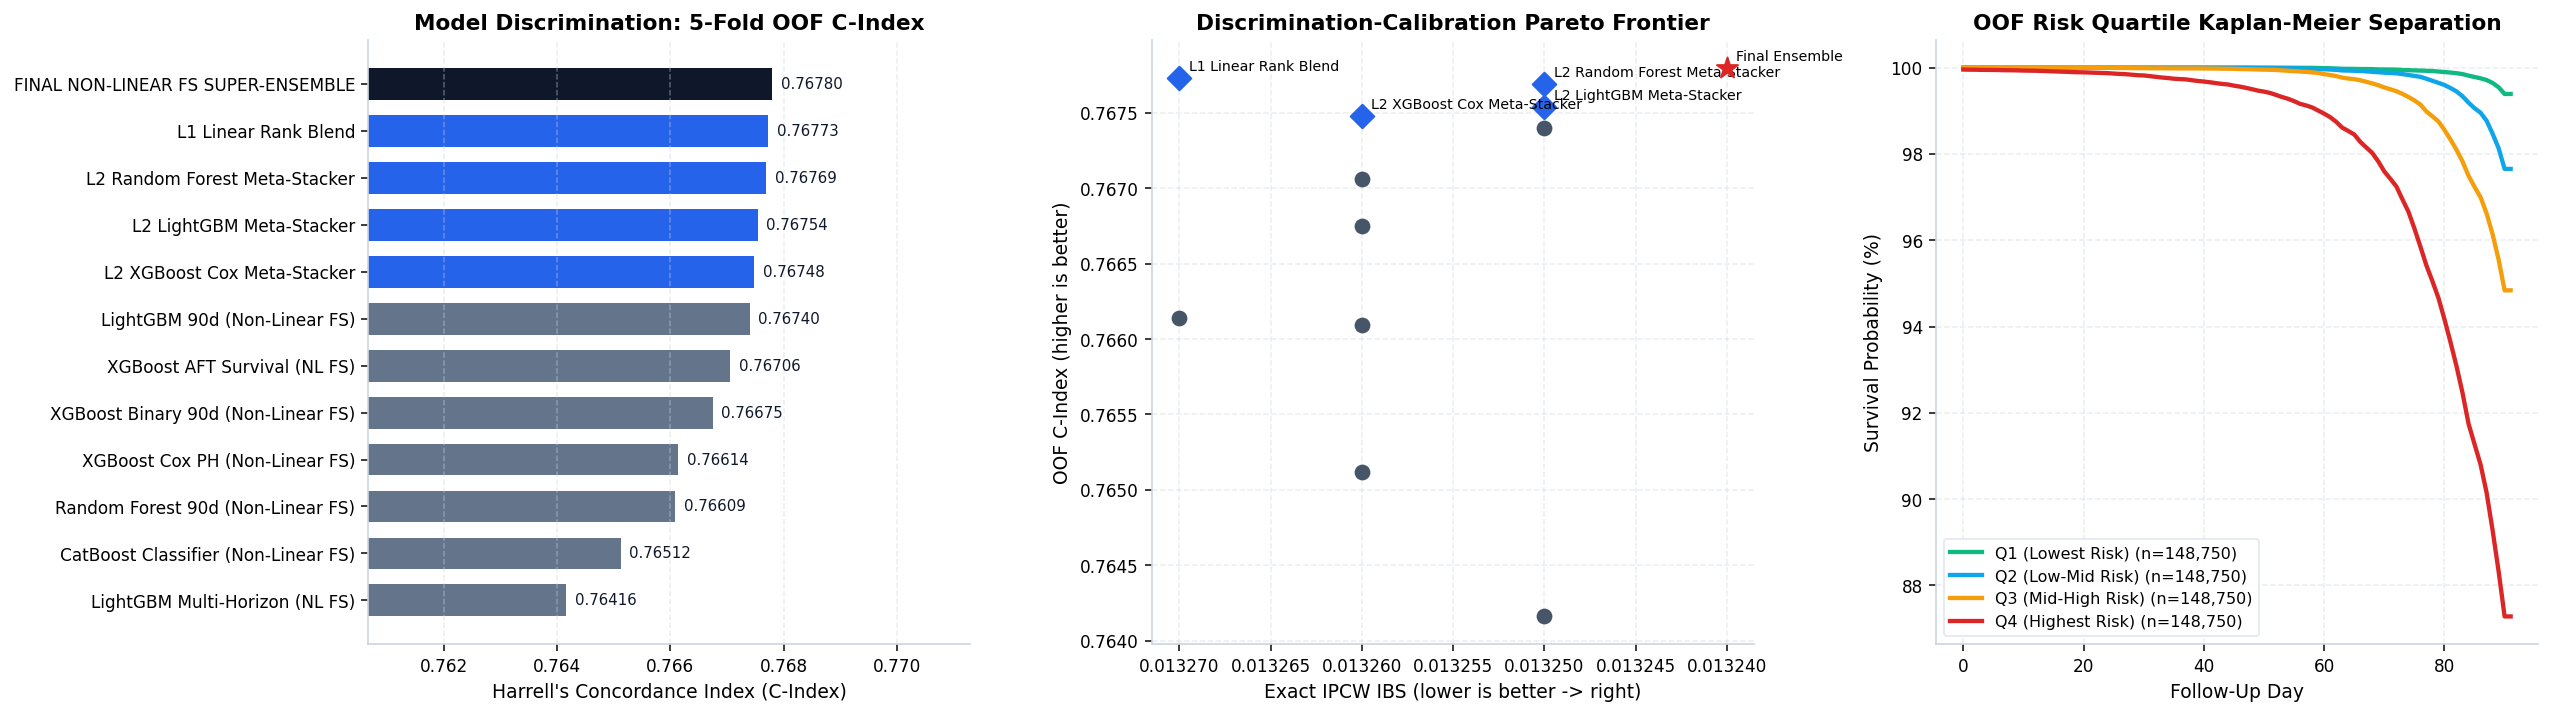

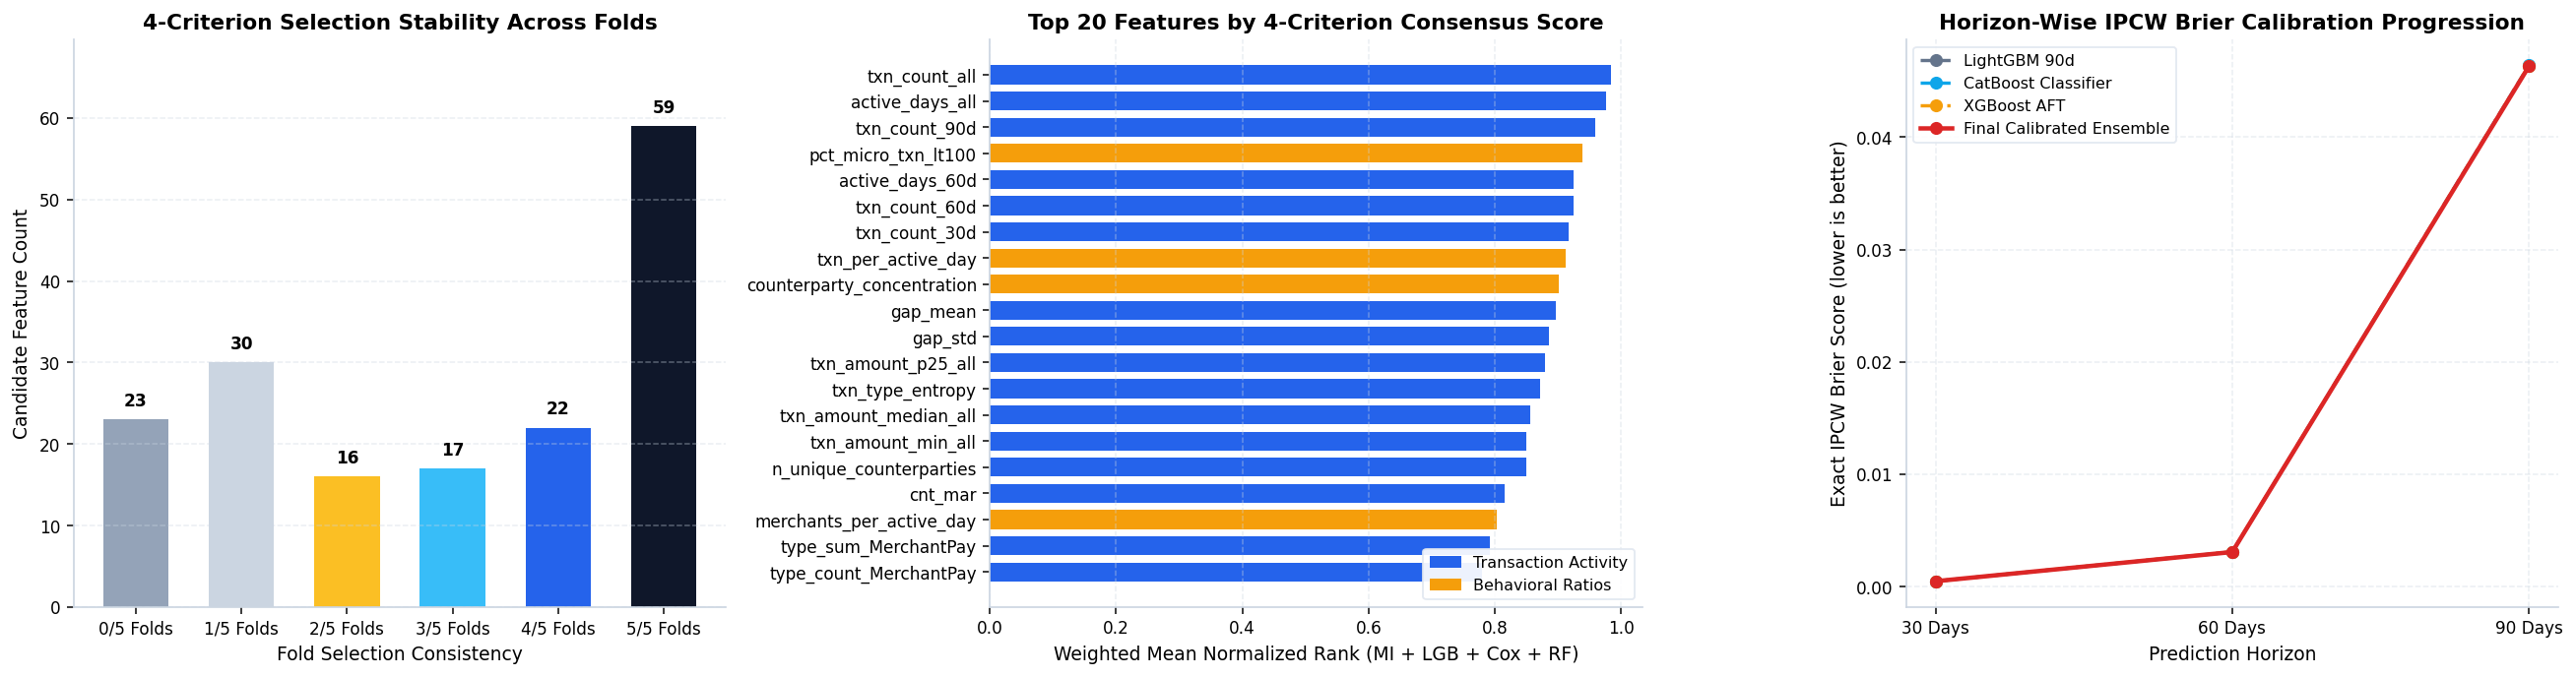

In [8]:
drop_cols = {"ACCOUNT_ID", "DURATION_DAYS", "EVENT_FLAG", "_act_tier", "_zero_tier", "_rec_tier"}
base_feature_cols = [c for c in train.columns if c not in drop_cols]

event = train["EVENT_FLAG"].astype(int).values
duration = train["DURATION_DAYS"].astype(float).values
dur_safe = np.maximum(duration, 0.5)  # Strictly positive survival times required by AFT/Cox objectives

# Joint stratification on event indicator and event-time quartiles preserves hazard distributions across folds
strat_key = np.zeros(len(train), dtype=np.int32)
strat_key[(event == 1) & (duration <= 60)] = 1
strat_key[(event == 1) & (duration > 60) & (duration <= 80)] = 2
strat_key[(event == 1) & (duration > 80)] = 3

N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(train, strat_key))

# Out-of-fold empirical Bayes smoothed target encodings on demographic cohorts
te_cols = [c for c in ["region_enc", "region_gender_enc", "open_year"] if c in train.columns]
global_ev = float(event.mean())
global_dur = float(duration.mean())
SMOOTH = 200.0

for col in te_cols:
    oof_ev_te = np.full(len(train), global_ev, dtype=np.float32)
    test_ev_te = np.zeros(len(test), dtype=np.float32)
    oof_du_te = np.full(len(train), global_dur, dtype=np.float32)
    test_du_te = np.zeros(len(test), dtype=np.float32)

    tr_s = train[col].astype(np.int64)
    te_s = test[col].astype(np.int64)
    for tr_i, va_i in folds:
        tmp = pd.DataFrame({"k": tr_s.iloc[tr_i].values, "ev": event[tr_i], "du": duration[tr_i]})
        agg = tmp.groupby("k").agg(cnt=("ev", "count"), ev_sum=("ev", "sum"), du_sum=("du", "sum"))
        ev_map = (agg["ev_sum"] + SMOOTH * global_ev) / (agg["cnt"] + SMOOTH)
        du_map = (agg["du_sum"] + SMOOTH * global_dur) / (agg["cnt"] + SMOOTH)

        oof_ev_te[va_i] = tr_s.iloc[va_i].map(ev_map).fillna(global_ev).values
        oof_du_te[va_i] = tr_s.iloc[va_i].map(du_map).fillna(global_dur).values
        test_ev_te += te_s.map(ev_map).fillna(global_ev).values / N_FOLDS
        test_du_te += te_s.map(du_map).fillna(global_dur).values / N_FOLDS

    train[f"{col}_te_ev"] = oof_ev_te
    test[f"{col}_te_ev"] = test_ev_te
    train[f"{col}_te_du"] = oof_du_te
    test[f"{col}_te_du"] = test_du_te

feature_cols = [c for c in train.columns if c not in drop_cols]
X = np.nan_to_num(train[feature_cols].to_numpy(dtype=np.float32), nan=0.0, posinf=0.0, neginf=0.0)
Xtest = np.nan_to_num(test[feature_cols].to_numpy(dtype=np.float32), nan=0.0, posinf=0.0, neginf=0.0)
n_total_feats = X.shape[1]

# Fold-isolated 4-criterion non-linear feature selection configuration
FS_N_TREE_PROBE = 45000
FS_N_MI_PROBE = 15000
FS_N_SHADOWS = 8
FS_MIN_KEEP = min(95, max(12, int(0.65 * n_total_feats)))
FS_MAX_KEEP = min(130, max(FS_MIN_KEEP, int(0.82 * n_total_feats)))


def _stratified_sample_idx(strata: np.ndarray, n_target: int, rng: np.random.Generator) -> np.ndarray:
    """Draw a deterministic proportional stratified subsample for fold probe estimation."""
    if len(strata) <= n_target:
        return np.arange(len(strata))
    uniq, cnts = np.unique(strata, return_counts=True)
    chosen = []
    for u, c in zip(uniq, cnts):
        pool = np.where(strata == u)[0]
        k = min(max(1, int(round(n_target * c / len(strata)))), len(pool))
        chosen.append(rng.choice(pool, size=k, replace=False))
    idx_out = np.concatenate(chosen)
    if len(idx_out) > n_target:
        idx_out = rng.choice(idx_out, size=n_target, replace=False)
    return np.sort(idx_out)


def _select_nonlinear_features_fold(X_tr_f, y90_tr, ev_tr, dur_tr, strata_tr, seed_f, xgb_device="cpu"):
    """
    Perform leak-free 4-criterion non-linear feature selection inside training fold tr_i:
      1) Mutual Information I(X_j; Y_90) for non-monotonic statistical dependency
      2) Shadow-gated LightGBM split gain against permutation noise (85th percentile floor)
      3) Shadow-gated XGBoost Cox PH gain conditioned on censored survival durations
      4) Shadow-gated Random Forest Gini impurity importance for bagging variance resistance
    """
    rng = np.random.default_rng(seed_f)
    p = X_tr_f.shape[1]

    stds = X_tr_f[:min(50000, len(X_tr_f))].std(axis=0)
    nonconst_mask = stds > 1e-8

    tree_idx = _stratified_sample_idx(strata_tr, FS_N_TREE_PROBE, rng)
    mi_idx = _stratified_sample_idx(strata_tr, FS_N_MI_PROBE, rng)

    X_tree = X_tr_f[tree_idx]
    y_tree = y90_tr[tree_idx]
    ev_p = ev_tr[tree_idx]
    dur_p = dur_tr[tree_idx]

    src_cols = rng.choice(np.where(nonconst_mask)[0] if nonconst_mask.any() else np.arange(p), size=FS_N_SHADOWS, replace=True)
    shadows = np.column_stack([rng.permutation(X_tree[:, c]) for c in src_cols]).astype(np.float32)
    X_aug = np.hstack([X_tree, shadows])

    mi_scores = np.zeros(p, dtype=np.float64)
    if nonconst_mask.any() and len(np.unique(y90_tr[mi_idx])) > 1:
        mi_raw = mutual_info_classif(X_tr_f[mi_idx][:, nonconst_mask], y90_tr[mi_idx], n_neighbors=5, random_state=seed_f)
        mi_scores[nonconst_mask] = np.maximum(mi_raw, 0.0)

    lgb_fs = lgb.LGBMClassifier(
        n_estimators=140, learning_rate=0.04, max_depth=5, num_leaves=31,
        colsample_bytree=0.70, subsample=0.80, subsample_freq=1,
        min_child_samples=max(10, min(60, len(X_tree) // 100)),
        n_jobs=-1, random_state=seed_f, verbose=-1
    )
    lgb_fs.fit(X_aug, y_tree)
    lgb_gain_all = lgb_fs.booster_.feature_importance(importance_type="gain").astype(np.float64)
    lgb_real, lgb_shad = lgb_gain_all[:p], lgb_gain_all[p:]
    lgb_floor = float(np.percentile(lgb_shad, 85)) if len(lgb_shad) else 0.0

    y_cox_p = np.where(ev_p == 1, dur_p, -dur_p)
    dm_p = xgb.DMatrix(X_aug, label=y_cox_p)
    cox_fs = xgb.train(
        {"objective": "survival:cox", "eval_metric": "cox-nloglik", "tree_method": "hist",
         "device": xgb_device, "max_depth": 4, "learning_rate": 0.04, "subsample": 0.80,
         "colsample_bytree": 0.70, "min_child_weight": max(5, min(30, len(X_tree) // 200)), "seed": seed_f},
        dm_p, num_boost_round=120, verbose_eval=False
    )
    score_dict = cox_fs.get_score(importance_type="gain")
    cox_all = np.array([score_dict.get(f"f{j}", 0.0) for j in range(p + FS_N_SHADOWS)], dtype=np.float64)
    cox_real, cox_shad = cox_all[:p], cox_all[p:]
    cox_floor = float(np.percentile(cox_shad, 85)) if len(cox_shad) else 0.0

    rf_fs = RandomForestClassifier(
        n_estimators=90, max_depth=10, min_samples_leaf=max(5, min(50, len(X_tree) // 250)),
        max_features=0.35, max_samples=0.65, n_jobs=-1, random_state=seed_f
    )
    rf_fs.fit(X_aug, y_tree)
    rf_all = rf_fs.feature_importances_.astype(np.float64)
    rf_real, rf_shad = rf_all[:p], rf_all[p:]
    rf_floor = float(np.percentile(rf_shad, 85)) if len(rf_shad) else 0.0

    cons_score = (
        0.25 * (rankdata(mi_scores) / p)
        + 0.30 * (rankdata(lgb_real) / p)
        + 0.25 * (rankdata(cox_real) / p)
        + 0.20 * (rankdata(rf_real) / p)
    )
    cons_score = np.where(nonconst_mask, cons_score, -1.0)

    # Retain features clearing the 85th-percentile permutation noise floor in at least one tree/survival paradigm
    passed_shadow = nonconst_mask & (
        (lgb_real > max(1e-9, lgb_floor))
        | (cox_real > max(1e-9, cox_floor))
        | (rf_real > max(1e-9, rf_floor))
    )
    ranked_desc = np.argsort(-cons_score)
    shadow_ranked = [int(j) for j in ranked_desc if passed_shadow[j]]

    if len(shadow_ranked) < FS_MIN_KEEP:
        chosen = [int(j) for j in ranked_desc if nonconst_mask[j]][:FS_MIN_KEEP]
    else:
        chosen = shadow_ranked[:FS_MAX_KEEP]
    sel_idx = np.array(sorted(chosen), dtype=np.int64)

    del X_aug, shadows, dm_p, lgb_fs, cox_fs, rf_fs
    return sel_idx, cons_score, mi_scores, lgb_real, cox_real, rf_real


ALL_HORIZONS = [30, 60, 75, 83, 90]
SUBMIT_HORIZONS = [30, 60, 90]
targets = {t: ((duration <= t) & (event == 1)).astype(np.int8) for t in ALL_HORIZONS}

LGB_BASE = dict(objective="binary", metric="auc", n_jobs=-1, seed=SEED, verbose=-1)
LGB_CONFIGS = {
    30: dict(LGB_BASE, learning_rate=0.02, num_leaves=31, feature_fraction=0.75, bagging_fraction=0.80, bagging_freq=1, min_child_samples=120, scale_pos_weight=15.0, reg_alpha=2.0, reg_lambda=5.0),
    60: dict(LGB_BASE, learning_rate=0.02, num_leaves=47, feature_fraction=0.75, bagging_fraction=0.80, bagging_freq=1, min_child_samples=80, scale_pos_weight=10.0, reg_alpha=2.0, reg_lambda=5.0),
    75: dict(LGB_BASE, learning_rate=0.02, num_leaves=63, feature_fraction=0.70, bagging_fraction=0.75, bagging_freq=1, min_child_samples=50, reg_alpha=3.0, reg_lambda=8.0),
    83: dict(LGB_BASE, learning_rate=0.02, num_leaves=95, feature_fraction=0.68, bagging_fraction=0.75, bagging_freq=1, min_child_samples=40, reg_alpha=4.0, reg_lambda=10.0),
    90: dict(LGB_BASE, learning_rate=0.018, num_leaves=111, feature_fraction=0.68, bagging_fraction=0.75, bagging_freq=1, min_child_samples=35, reg_alpha=5.0, reg_lambda=12.0),
}

lgb_oof = {t: np.zeros(len(X), dtype=np.float64) for t in ALL_HORIZONS}
lgb_test = {t: np.zeros(len(Xtest), dtype=np.float64) for t in ALL_HORIZONS}
cb_oof = {t: np.zeros(len(X), dtype=np.float64) for t in [60, 90]}
cb_test = {t: np.zeros(len(Xtest), dtype=np.float64) for t in [60, 90]}
xgb_bin_oof = np.zeros(len(X), dtype=np.float64)
xgb_bin_test = np.zeros(len(Xtest), dtype=np.float64)
xgb_aft_oof = np.zeros(len(X), dtype=np.float64)
xgb_aft_test = np.zeros(len(Xtest), dtype=np.float64)
xgb_cox_oof = np.zeros(len(X), dtype=np.float64)
xgb_cox_test = np.zeros(len(Xtest), dtype=np.float64)
rf_oof = np.zeros(len(X), dtype=np.float64)
rf_test = np.zeros(len(Xtest), dtype=np.float64)

fs_votes = np.zeros(n_total_feats, dtype=np.int32)
fs_cons = np.zeros(n_total_feats, dtype=np.float64)
fs_mi = np.zeros(n_total_feats, dtype=np.float64)
fs_lgb = np.zeros(n_total_feats, dtype=np.float64)
fs_cox = np.zeros(n_total_feats, dtype=np.float64)
fs_rf = np.zeros(n_total_feats, dtype=np.float64)
gain_imp = np.zeros(n_total_feats, dtype=np.float64)

xgb_dev = "cuda" if HAS_XGB_CUDA else "cpu"
cb_task = "GPU" if HAS_CB_GPU else "CPU"
fold_logs = []

# Unified 5-fold CV: fold-isolated non-linear feature selection paired with Level-1 training
for fold, (tr_i, va_i) in enumerate(folds):
    t_f0 = time.time()

    sel_idx, c_sc, mi_sc, lgb_sc, cox_sc, rf_sc = _select_nonlinear_features_fold(
        X[tr_i], targets[90][tr_i], event[tr_i], dur_safe[tr_i], strat_key[tr_i],
        seed_f=SEED + 500 + fold, xgb_device=xgb_dev
    )
    fs_votes[sel_idx] += 1
    fs_cons += c_sc / N_FOLDS
    fs_mi += mi_sc / N_FOLDS
    fs_lgb += lgb_sc / N_FOLDS
    fs_cox += cox_sc / N_FOLDS
    fs_rf += rf_sc / N_FOLDS

    sel_names = [feature_cols[j] for j in sel_idx]
    X_tr_s = X[tr_i][:, sel_idx]
    X_va_s = X[va_i][:, sel_idx]
    X_te_s = Xtest[:, sel_idx]

    for t in ALL_HORIZONS:
        y = targets[t]
        dtr = lgb.Dataset(X_tr_s, label=y[tr_i], feature_name=sel_names)
        dva = lgb.Dataset(X_va_s, label=y[va_i], reference=dtr)
        m = lgb.train(LGB_CONFIGS[t], dtr, num_boost_round=2500, valid_sets=[dva], callbacks=[lgb.early_stopping(120, verbose=False)])
        lgb_oof[t][va_i] = m.predict(X_va_s, num_iteration=m.best_iteration)
        lgb_test[t] += m.predict(X_te_s, num_iteration=m.best_iteration) / N_FOLDS
        if t == 90:
            gain_imp[sel_idx] += m.feature_importance("gain") / N_FOLDS
        del dtr, dva, m

    if HAS_CATBOOST:
        for t in [60, 90]:
            y = targets[t]
            cb = CatBoostClassifier(
                iterations=2200, learning_rate=0.035, depth=7, l2_leaf_reg=10.0,
                eval_metric="Logloss", random_seed=SEED + fold, task_type=cb_task, verbose=False
            )
            cb.fit(X_tr_s, y[tr_i], eval_set=(X_va_s, y[va_i]), early_stopping_rounds=120, verbose=False)
            cb_oof[t][va_i] = cb.predict_proba(X_va_s)[:, 1]
            cb_test[t] += cb.predict_proba(X_te_s)[:, 1] / N_FOLDS
            del cb

    dtest_xgb_s = xgb.DMatrix(X_te_s)

    dtr_b = xgb.DMatrix(X_tr_s, label=targets[90][tr_i])
    dva_b = xgb.DMatrix(X_va_s, label=targets[90][va_i])
    mb = xgb.train(
        {"objective": "binary:logistic", "eval_metric": "auc", "tree_method": "hist", "device": xgb_dev,
         "max_depth": 6, "learning_rate": 0.025, "subsample": 0.8, "colsample_bytree": 0.70,
         "min_child_weight": 30, "reg_alpha": 4.0, "reg_lambda": 10.0, "seed": SEED + fold},
        dtr_b, num_boost_round=2000, evals=[(dva_b, "val")], early_stopping_rounds=100, verbose_eval=False
    )
    xgb_bin_oof[va_i] = mb.predict(dva_b, iteration_range=(0, mb.best_iteration + 1))
    xgb_bin_test += mb.predict(dtest_xgb_s, iteration_range=(0, mb.best_iteration + 1)) / N_FOLDS

    dtr_a = xgb.DMatrix(X_tr_s)
    dtr_a.set_float_info("label_lower_bound", dur_safe[tr_i])
    dtr_a.set_float_info("label_upper_bound", np.where(event[tr_i] == 1, dur_safe[tr_i], np.inf))
    dva_a = xgb.DMatrix(X_va_s)
    dva_a.set_float_info("label_lower_bound", dur_safe[va_i])
    dva_a.set_float_info("label_upper_bound", np.where(event[va_i] == 1, dur_safe[va_i], np.inf))
    ma = xgb.train(
        {"objective": "survival:aft", "eval_metric": "aft-nloglik", "aft_loss_distribution": "normal",
         "aft_loss_distribution_scale": 1.1, "tree_method": "hist", "device": xgb_dev,
         "max_depth": 6, "learning_rate": 0.03, "subsample": 0.8, "colsample_bytree": 0.72,
         "min_child_weight": 30, "reg_lambda": 10.0, "seed": SEED + fold},
        dtr_a, num_boost_round=1500, evals=[(dva_a, "val")], early_stopping_rounds=80, verbose_eval=False
    )
    xgb_aft_oof[va_i] = 1.0 / np.clip(ma.predict(dva_a, iteration_range=(0, ma.best_iteration + 1)), 1e-6, None)
    xgb_aft_test += (1.0 / np.clip(ma.predict(dtest_xgb_s, iteration_range=(0, ma.best_iteration + 1)), 1e-6, None)) / N_FOLDS

    # Signed duration convention required by XGBoost Cox: positive for uncensored events, negative for censored
    y_cox_tr = np.where(event[tr_i] == 1, dur_safe[tr_i], -dur_safe[tr_i])
    y_cox_va = np.where(event[va_i] == 1, dur_safe[va_i], -dur_safe[va_i])
    dtr_c = xgb.DMatrix(X_tr_s, label=y_cox_tr)
    dva_c = xgb.DMatrix(X_va_s, label=y_cox_va)
    mc = xgb.train(
        {"objective": "survival:cox", "eval_metric": "cox-nloglik", "tree_method": "hist", "device": xgb_dev,
         "max_depth": 5, "learning_rate": 0.025, "subsample": 0.8, "colsample_bytree": 0.70,
         "min_child_weight": 30, "reg_alpha": 4.0, "reg_lambda": 12.0, "seed": SEED + fold},
        dtr_c, num_boost_round=1500, evals=[(dva_c, "val")], early_stopping_rounds=80, verbose_eval=False
    )
    xgb_cox_oof[va_i] = mc.predict(dva_c, iteration_range=(0, mc.best_iteration + 1))
    xgb_cox_test += mc.predict(dtest_xgb_s, iteration_range=(0, mc.best_iteration + 1)) / N_FOLDS

    rf_k = RandomForestClassifier(
        n_estimators=180,
        max_depth=14,
        min_samples_leaf=min(80, max(5, len(tr_i) // 500)),
        max_features=0.35,
        max_samples=0.40,
        bootstrap=True,
        n_jobs=-1,
        random_state=SEED + 700 + fold,
    )
    rf_k.fit(X_tr_s, targets[90][tr_i])
    rf_oof[va_i] = rf_k.predict_proba(X_va_s)[:, 1]
    rf_test += rf_k.predict_proba(X_te_s)[:, 1] / N_FOLDS

    fold_logs.append({
        "Fold": f"{fold + 1} / {N_FOLDS}",
        "Train N": len(tr_i),
        "Valid N": len(va_i),
        "Selected": int(len(sel_idx)),
        "Pruned": int(n_total_feats - len(sel_idx)),
        "Retained (%)": round(100.0 * len(sel_idx) / max(1, n_total_feats), 1),
        "Elapsed (s)": round(time.time() - t_f0, 1),
    })
    del dtest_xgb_s, dtr_b, dva_b, mb, dtr_a, dva_a, ma, dtr_c, dva_c, mc, rf_k, X_tr_s, X_va_s, X_te_s
    gc.collect()

if not HAS_CATBOOST:
    for t in [60, 90]:
        cb_oof[t] = lgb_oof[t].copy()
        cb_test[t] = lgb_test[t].copy()

fold_log_df = pd.DataFrame(fold_logs)
display_table(
    fold_log_df,
    title="5-Fold Feature Selection and Level-1 Training Summary",
    fmt={"Train N": "{:,}", "Valid N": "{:,}", "Retained (%)": "{:.1f}", "Elapsed (s)": "{:.1f}"}
)

lgb_multi_oof = (0.02 * rankdata(lgb_oof[30]) + 0.05 * rankdata(lgb_oof[60]) + 0.13 * rankdata(lgb_oof[75]) + 0.25 * rankdata(lgb_oof[83]) + 0.55 * rankdata(lgb_oof[90])) / len(X)
lgb_multi_test = (0.02 * rankdata(lgb_test[30]) + 0.05 * rankdata(lgb_test[60]) + 0.13 * rankdata(lgb_test[75]) + 0.25 * rankdata(lgb_test[83]) + 0.55 * rankdata(lgb_test[90])) / len(Xtest)


def _safe_logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-6, 1.0 - 1e-6)
    return np.log(p / (1.0 - p))


rank_mat_oof = np.column_stack([
    rankdata(lgb_oof[90]) / len(X),
    lgb_multi_oof,
    rankdata(cb_oof[90]) / len(X),
    rankdata(xgb_bin_oof) / len(X),
    rankdata(xgb_aft_oof) / len(X),
    rankdata(xgb_cox_oof) / len(X),
    rankdata(rf_oof) / len(X),
])
rank_mat_test = np.column_stack([
    rankdata(lgb_test[90]) / len(Xtest),
    lgb_multi_test,
    rankdata(cb_test[90]) / len(Xtest),
    rankdata(xgb_bin_test) / len(Xtest),
    rankdata(xgb_aft_test) / len(Xtest),
    rankdata(xgb_cox_test) / len(Xtest),
    rankdata(rf_test) / len(Xtest),
])

r5_oof = rank_mat_oof[:, [0, 2, 3, 4, 5]]
r5_test = rank_mat_test[:, [0, 2, 3, 4, 5]]

# Top 8 consensus behavioral context features ranked by 4-criterion non-linear score
top_ctx_idx = np.argsort(-fs_cons)[:8]
Z_oof = np.column_stack([
    _safe_logit(lgb_oof[30]), _safe_logit(lgb_oof[60]), _safe_logit(lgb_oof[75]),
    _safe_logit(lgb_oof[83]), _safe_logit(lgb_oof[90]), lgb_multi_oof,
    _safe_logit(cb_oof[60]), _safe_logit(cb_oof[90]), _safe_logit(xgb_bin_oof),
    _safe_logit(rf_oof),
    np.log1p(np.clip(xgb_aft_oof, 0.0, 1e4)),
    np.log1p(np.clip(xgb_cox_oof, 0.0, 1e4)),
    r5_oof.std(axis=1),
    r5_oof.max(axis=1) - r5_oof.min(axis=1),
    rank_mat_oof[:, 4] - rank_mat_oof[:, 0],
    rank_mat_oof[:, 5] - rank_mat_oof[:, 2],
    rank_mat_oof[:, 0] - rank_mat_oof[:, 2],
    lgb_oof[90] - lgb_oof[75],
    lgb_oof[90] - lgb_oof[60],
    X[:, top_ctx_idx],
]).astype(np.float32)

Z_test = np.column_stack([
    _safe_logit(lgb_test[30]), _safe_logit(lgb_test[60]), _safe_logit(lgb_test[75]),
    _safe_logit(lgb_test[83]), _safe_logit(lgb_test[90]), lgb_multi_test,
    _safe_logit(cb_test[60]), _safe_logit(cb_test[90]), _safe_logit(xgb_bin_test),
    _safe_logit(rf_test),
    np.log1p(np.clip(xgb_aft_test, 0.0, 1e4)),
    np.log1p(np.clip(xgb_cox_test, 0.0, 1e4)),
    r5_test.std(axis=1),
    r5_test.max(axis=1) - r5_test.min(axis=1),
    rank_mat_test[:, 4] - rank_mat_test[:, 0],
    rank_mat_test[:, 5] - rank_mat_test[:, 2],
    rank_mat_test[:, 0] - rank_mat_test[:, 2],
    lgb_test[90] - lgb_test[75],
    lgb_test[90] - lgb_test[60],
    Xtest[:, top_ctx_idx],
]).astype(np.float32)

Z_oof = np.nan_to_num(Z_oof, nan=0.0, posinf=10.0, neginf=-10.0)
Z_test = np.nan_to_num(Z_test, nan=0.0, posinf=10.0, neginf=-10.0)

l2_lgb_oof = np.zeros(len(X), dtype=np.float64)
l2_lgb_test = np.zeros(len(Xtest), dtype=np.float64)
l2_cox_oof = np.zeros(len(X), dtype=np.float64)
l2_cox_test = np.zeros(len(Xtest), dtype=np.float64)
l2_rf_oof = np.zeros(len(X), dtype=np.float64)
l2_rf_test = np.zeros(len(Xtest), dtype=np.float64)

dtest_z = xgb.DMatrix(Z_test)
for fold, (tr_i, va_i) in enumerate(folds):
    dtr_m = lgb.Dataset(Z_oof[tr_i], label=targets[90][tr_i])
    dva_m = lgb.Dataset(Z_oof[va_i], label=targets[90][va_i], reference=dtr_m)
    m_l2_lgb = lgb.train(
        {"objective": "binary", "metric": "binary_logloss", "learning_rate": 0.02,
         "max_depth": 3, "num_leaves": 7, "min_child_samples": 200,
         "feature_fraction": 0.75, "bagging_fraction": 0.80, "bagging_freq": 1,
         "reg_alpha": 5.0, "reg_lambda": 25.0, "n_jobs": -1, "seed": SEED + 100 + fold, "verbose": -1},
        dtr_m, num_boost_round=1200, valid_sets=[dva_m], callbacks=[lgb.early_stopping(80, verbose=False)]
    )
    l2_lgb_oof[va_i] = m_l2_lgb.predict(Z_oof[va_i], num_iteration=m_l2_lgb.best_iteration)
    l2_lgb_test += m_l2_lgb.predict(Z_test, num_iteration=m_l2_lgb.best_iteration) / N_FOLDS

    y_cox_tr = np.where(event[tr_i] == 1, dur_safe[tr_i], -dur_safe[tr_i])
    y_cox_va = np.where(event[va_i] == 1, dur_safe[va_i], -dur_safe[va_i])
    dtr_mc = xgb.DMatrix(Z_oof[tr_i], label=y_cox_tr)
    dva_mc = xgb.DMatrix(Z_oof[va_i], label=y_cox_va)
    m_l2_cox = xgb.train(
        {"objective": "survival:cox", "eval_metric": "cox-nloglik", "tree_method": "hist", "device": xgb_dev,
         "max_depth": 3, "learning_rate": 0.02, "subsample": 0.80, "colsample_bytree": 0.75,
         "min_child_weight": 80, "reg_alpha": 5.0, "reg_lambda": 30.0, "seed": SEED + 200 + fold},
        dtr_mc, num_boost_round=1000, evals=[(dva_mc, "val")], early_stopping_rounds=60, verbose_eval=False
    )
    l2_cox_oof[va_i] = m_l2_cox.predict(dva_mc, iteration_range=(0, m_l2_cox.best_iteration + 1))
    l2_cox_test += m_l2_cox.predict(dtest_z, iteration_range=(0, m_l2_cox.best_iteration + 1)) / N_FOLDS

    l2_rf = RandomForestClassifier(
        n_estimators=220,
        max_depth=6,
        min_samples_leaf=min(200, max(5, len(tr_i) // 300)),
        max_features=0.55,
        max_samples=0.70,
        bootstrap=True,
        n_jobs=-1,
        random_state=SEED + 300 + fold,
    )
    l2_rf.fit(Z_oof[tr_i], targets[90][tr_i])
    l2_rf_oof[va_i] = l2_rf.predict_proba(Z_oof[va_i])[:, 1]
    l2_rf_test += l2_rf.predict_proba(Z_test)[:, 1] / N_FOLDS

# Multi-start Powell simplex optimization guarded against full-OOF degradation
ev_idx = np.where(event == 1)[0]
ne_idx = np.where(event == 0)[0]
rng_opt = np.random.default_rng(SEED)
sub_opt = np.concatenate([ev_idx, rng_opt.choice(ne_idx, size=min(150000, len(ne_idx)), replace=False)])


def _opt_weights(mat_oof):
    k_cols = mat_oof.shape[1]
    col_scores = np.array([exact_concordance_index_censored(event[sub_opt].astype(bool), duration[sub_opt], mat_oof[sub_opt, j])[0] for j in range(k_cols)])
    best_j = int(np.argmax(col_scores))
    w_best_single = np.zeros(k_cols)
    w_best_single[best_j] = 1.0
    w_top2 = np.zeros(k_cols)
    top2_idx = np.argsort(col_scores)[-min(2, k_cols):]
    w_top2[top2_idx] = 1.0 / len(top2_idx)
    starts = [np.ones(k_cols) / k_cols, w_top2, w_best_single]

    def _neg_c(raw_w):
        w = np.maximum(raw_w, 0.0)
        if w.sum() <= 1e-12:
            return 0.0
        w /= w.sum()
        return -exact_concordance_index_censored(event[sub_opt].astype(bool), duration[sub_opt], mat_oof[sub_opt] @ w)[0]

    best_w, best_val = w_top2, _neg_c(w_top2)
    for x0 in starts:
        res = minimize(_neg_c, x0=x0, method="Powell", options={"maxiter": 250})
        w = np.maximum(res.x, 0.0)
        if w.sum() > 0:
            w = w / w.sum()
            val = _neg_c(w)
            if val < best_val:
                best_val, best_w = val, w
    return best_w


w_l1 = _opt_weights(rank_mat_oof)
l1_blend_oof = rank_mat_oof @ w_l1
l1_blend_test = rank_mat_test @ w_l1

stack_cand_oof = np.column_stack([
    l1_blend_oof,
    rankdata(l2_lgb_oof) / len(X),
    rankdata(l2_cox_oof) / len(X),
    rankdata(l2_rf_oof) / len(X),
])
stack_cand_test = np.column_stack([
    l1_blend_test,
    rankdata(l2_lgb_test) / len(Xtest),
    rankdata(l2_cox_test) / len(Xtest),
    rankdata(l2_rf_test) / len(Xtest),
])
w_l2 = _opt_weights(stack_cand_oof)
stack_names = ["L1_LinearBlend", "L2_LGB_Meta", "L2_XGB_Cox_Meta", "L2_RF_Meta"]

full_cands = {
    "powell_l2": (stack_cand_oof @ w_l2, stack_cand_test @ w_l2, w_l2),
    "lgb_cox_50_50": (
        0.5 * stack_cand_oof[:, 1] + 0.5 * stack_cand_oof[:, 2],
        0.5 * stack_cand_test[:, 1] + 0.5 * stack_cand_test[:, 2],
        np.array([0.0, 0.5, 0.5, 0.0])
    ),
    "lgb_cox_70_30": (
        0.7 * stack_cand_oof[:, 1] + 0.3 * stack_cand_oof[:, 2],
        0.7 * stack_cand_test[:, 1] + 0.3 * stack_cand_test[:, 2],
        np.array([0.0, 0.7, 0.3, 0.0])
    ),
}
for j, nm in enumerate(stack_names):
    w_s = np.zeros(len(stack_names))
    w_s[j] = 1.0
    full_cands[f"only_{nm}"] = (stack_cand_oof[:, j], stack_cand_test[:, j], w_s)

best_key = max(full_cands, key=lambda k: float(concordance_index_censored(event.astype(bool), duration, full_cands[k][0])[0]))
risk_oof, risk_test, w_final = full_cands[best_key]

# Optimize 90d probability combination and perform horizon-wise OOF calibration under monotonicity S(30) >= S(60) >= S(90)
p90_names = ["LGB90", "CB90", "XGB90", "RF90", "L2_LGB", "L2_RF"]
p90_mat_oof = np.column_stack([lgb_oof[90], cb_oof[90], xgb_bin_oof, rf_oof, l2_lgb_oof, l2_rf_oof])
p90_mat_test = np.column_stack([lgb_test[90], cb_test[90], xgb_bin_test, rf_test, l2_lgb_test, l2_rf_test])


def _brier90(raw_w):
    w = np.maximum(raw_w, 0.0)
    if w.sum() <= 1e-12:
        return 1.0
    w /= w.sum()
    return float(np.mean((targets[90] - (p90_mat_oof @ w)) ** 2))


res_b90 = minimize(_brier90, x0=np.ones(p90_mat_oof.shape[1]) / p90_mat_oof.shape[1], method="Powell")
w_b90 = np.maximum(res_b90.x, 0.0)
w_b90 = w_b90 / w_b90.sum() if w_b90.sum() > 0 else np.ones(p90_mat_oof.shape[1]) / p90_mat_oof.shape[1]

blend_weights_df = pd.DataFrame([
    {"Optimization Stage": f"Risk Ranking Blend ({best_key})", "Component": nm, "Weight": round(float(w), 4)}
    for nm, w in zip(stack_names, w_final)
] + [
    {"Optimization Stage": "90-Day Brier Probability Blend", "Component": nm, "Weight": round(float(w), 4)}
    for nm, w in zip(p90_names, w_b90)
])
display_table(blend_weights_df, title="Optimized Meta-Ensemble Risk and 90-Day Calibration Weights", fmt={"Weight": "{:.4f}"})

raw_p_oof = {30: lgb_oof[30], 60: 0.55 * lgb_oof[60] + 0.45 * cb_oof[60], 90: p90_mat_oof @ w_b90}
raw_p_test = {30: lgb_test[30], 60: 0.55 * lgb_test[60] + 0.45 * cb_test[60], 90: p90_mat_test @ w_b90}


def _calibrate_oof_prob(raw_oof_p, raw_te_p, y_t):
    iso_o = np.zeros(len(X), dtype=np.float64)
    iso_t = np.zeros(len(Xtest), dtype=np.float64)
    lr_o = np.zeros(len(X), dtype=np.float64)
    lr_t = np.zeros(len(Xtest), dtype=np.float64)
    has_lr = True
    for tr_i, va_i in folds:
        iso = IsotonicRegression(out_of_bounds="clip").fit(raw_oof_p[tr_i], y_t[tr_i])
        iso_o[va_i] = np.clip(iso.predict(raw_oof_p[va_i]), 1e-6, 1.0 - 1e-6)
        iso_t += np.clip(iso.predict(raw_te_p), 1e-6, 1.0 - 1e-6) / N_FOLDS
        if int(y_t[tr_i].sum()) >= 5:
            sc = StandardScaler().fit(Z_oof[tr_i, :19])
            lr = LogisticRegression(C=0.25, max_iter=1000).fit(sc.transform(Z_oof[tr_i, :19]), y_t[tr_i])
            lr_o[va_i] = np.clip(lr.predict_proba(sc.transform(Z_oof[va_i, :19]))[:, 1], 1e-6, 1.0 - 1e-6)
            lr_t += np.clip(lr.predict_proba(sc.transform(Z_test[:, :19]))[:, 1], 1e-6, 1.0 - 1e-6) / N_FOLDS
        else:
            has_lr = False
    if not has_lr:
        return iso_o, iso_t, "iso"
    cands = {
        "raw_l2": (np.clip(raw_oof_p, 1e-6, 1.0 - 1e-6), np.clip(raw_te_p, 1e-6, 1.0 - 1e-6)),
        "iso": (iso_o, iso_t),
        "lr": (lr_o, lr_t),
        "hybrid": (0.5 * lr_o + 0.5 * iso_o, 0.5 * lr_t + 0.5 * iso_t),
    }
    best_name = min(cands, key=lambda k: float(np.mean((y_t - cands[k][0]) ** 2)))
    return cands[best_name][0], cands[best_name][1], best_name


oof_c, test_c, cal_rows = {}, {}, []
for t in SUBMIT_HORIZONS:
    oof_c[t], test_c[t], best_cal = _calibrate_oof_prob(raw_p_oof[t], raw_p_test[t], targets[t])
    cal_rows.append({"Horizon (Days)": t, "Selected Calibrator": best_cal, "OOF Brier Score": float(np.mean((targets[t] - oof_c[t]) ** 2))})
display_table(pd.DataFrame(cal_rows), title="Horizon Survival Probability Calibration Summary", fmt={"OOF Brier Score": "{:.5f}"})


def enforce_monotone(pdict):
    p30, p60, p90 = pdict[30].copy(), pdict[60].copy(), pdict[90].copy()
    p60 = np.maximum(p30, p60)
    p90 = np.maximum(p60, p90)
    return {30: p30, 60: p60, 90: p90}


oof_m, test_m = enforce_monotone(oof_c), enforce_monotone(test_c)
oof_S = {t: 1.0 - oof_m[t] for t in SUBMIT_HORIZONS}
test_S = {t: 1.0 - test_m[t] for t in SUBMIT_HORIZONS}

# Exact 5-fold cross-validation evaluation and feature selection stability audit
y_str = Surv.from_arrays(event=event.astype(bool), time=duration)


def _quick_iso_curve(p30_raw, p60_raw, p90_raw):
    s_out = {}
    for t, r_raw in [(30, p30_raw), (60, p60_raw), (90, p90_raw)]:
        cal_p = np.zeros(len(X), dtype=np.float64)
        yt = targets[t]
        for tr_i, va_i in folds:
            iso_k = IsotonicRegression(out_of_bounds="clip").fit(r_raw[tr_i], yt[tr_i])
            cal_p[va_i] = np.clip(iso_k.predict(r_raw[va_i]), 1e-6, 1.0 - 1e-6)
        s_out[t] = 1.0 - cal_p
    s_out[60] = np.minimum(s_out[30], s_out[60])
    s_out[90] = np.minimum(s_out[60], s_out[90])
    return s_out


def _eval_row(model_name, risk_vec, s_dict):
    ci = float(concordance_index_censored(event.astype(bool), duration, risk_vec)[0])
    bs_unw = {t: float(np.mean(((duration > t).astype(float) - s_dict[t]) ** 2)) for t in SUBMIT_HORIZONS}
    s_mat = np.column_stack([s_dict[30], s_dict[60], s_dict[90]])
    ipcw_bs, _ = exact_ipcw_brier_at_times(y_str, y_str, s_mat, np.array(SUBMIT_HORIZONS))
    ibs_sk_val = float(integrated_brier_score(y_str, y_str, s_mat, np.array(SUBMIT_HORIZONS)))
    return {
        "model": model_name,
        "oof_c_index": round(ci, 5),
        "brier_30d": round(bs_unw[30], 5),
        "brier_60d": round(bs_unw[60], 5),
        "brier_90d": round(bs_unw[90], 5),
        "mean_brier": round(float(np.mean(list(bs_unw.values()))), 5),
        "ipcw_brier_30d": round(ipcw_bs[30], 5),
        "ipcw_brier_60d": round(ipcw_bs[60], 5),
        "ipcw_brier_90d": round(ipcw_bs[90], 5),
        "exact_ipcw_ibs": round(ibs_sk_val, 5),
    }


metrics_rows = [
    _eval_row("LightGBM 90d (Non-Linear FS)", lgb_oof[90], _quick_iso_curve(lgb_oof[30], lgb_oof[60], lgb_oof[90])),
    _eval_row("LightGBM Multi-Horizon (NL FS)", lgb_multi_oof, _quick_iso_curve(lgb_oof[30], lgb_oof[60], lgb_oof[90])),
    _eval_row("CatBoost Classifier (Non-Linear FS)", cb_oof[90], _quick_iso_curve(lgb_oof[30], cb_oof[60], cb_oof[90])),
    _eval_row("XGBoost Binary 90d (Non-Linear FS)", xgb_bin_oof, _quick_iso_curve(xgb_bin_oof, xgb_bin_oof, xgb_bin_oof)),
    _eval_row("XGBoost AFT Survival (NL FS)", xgb_aft_oof, _quick_iso_curve(xgb_aft_oof, xgb_aft_oof, xgb_aft_oof)),
    _eval_row("XGBoost Cox PH (Non-Linear FS)", xgb_cox_oof, _quick_iso_curve(xgb_cox_oof, xgb_cox_oof, xgb_cox_oof)),
    _eval_row("Random Forest 90d (Non-Linear FS)", rf_oof, _quick_iso_curve(lgb_oof[30], lgb_oof[60], rf_oof)),
    _eval_row("L1 Linear Rank Blend", l1_blend_oof, _quick_iso_curve(l1_blend_oof, l1_blend_oof, l1_blend_oof)),
    _eval_row("L2 LightGBM Meta-Stacker", l2_lgb_oof, _quick_iso_curve(oof_m[30], oof_m[60], l2_lgb_oof)),
    _eval_row("L2 XGBoost Cox Meta-Stacker", l2_cox_oof, _quick_iso_curve(l2_cox_oof, l2_cox_oof, l2_cox_oof)),
    _eval_row("L2 Random Forest Meta-Stacker", l2_rf_oof, _quick_iso_curve(oof_m[30], oof_m[60], l2_rf_oof)),
    _eval_row("FINAL NON-LINEAR FS SUPER-ENSEMBLE", risk_oof, oof_S),
]
metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(OUTPUT_DIR / "nonlinear_fs_ensemble_metrics.csv", index=False)


def _classify_feature_domain(name: str) -> str:
    if name.endswith("_te_ev") or name.endswith("_te_du") or name in {"account_tenure_days", "open_year", "open_month", "gender_enc", "region_enc", "account_type_enc", "region_gender_enc"}:
        return "KYC & Cohort TE"
    if name.startswith("bal_") or name in {"n_balance_records", "zero_bal_days", "zero_bal_ratio", "days_since_last_bal_move", "balance_weekly_slope", "slope_h1", "slope_h2", "balance_acceleration"}:
        return "Balance Physics"
    if any(k in name for k in ["_ratio", "_diff_", "_slope", "_share", "_per_", "_vs_", "net_flow", "decline_", "decay_", "overdue_", "gap_zscore", "concentration", "skew_proxy", "iqr", "pct_"]):
        return "Behavioral Ratios"
    return "Transaction Activity"


fs_report_df = pd.DataFrame({
    "overall_rank": np.arange(1, len(feature_cols) + 1),
    "feature": feature_cols,
    "domain": [ _classify_feature_domain(c) for c in feature_cols ],
    "folds_selected": fs_votes,
    "nonlinear_consensus_score": np.round(fs_cons, 5),
    "mutual_info": np.round(fs_mi, 6),
    "lgb_probe_gain": np.round(fs_lgb, 2),
    "xgb_cox_probe_gain": np.round(fs_cox, 2),
    "rf_probe_imp": np.round(fs_rf, 6),
    "full_lgb90_gain": np.round(gain_imp, 2),
}).sort_values(["folds_selected", "nonlinear_consensus_score"], ascending=False).reset_index(drop=True)
fs_report_df["overall_rank"] = np.arange(1, len(fs_report_df) + 1)
fs_report_df.to_csv(OUTPUT_DIR / "nonlinear_feature_selection_report.csv", index=False)

if Path("/kaggle/working").exists():
    metrics_df.to_csv("/kaggle/working/nonlinear_fs_ensemble_metrics.csv", index=False)
    fs_report_df.to_csv("/kaggle/working/nonlinear_feature_selection_report.csv", index=False)

final_row = metrics_rows[-1]
c_index = final_row["oof_c_index"]
ibs_mean = final_row["mean_brier"]
ibs_sk = final_row["exact_ipcw_ibs"]
bs = {30: final_row["brier_30d"], 60: final_row["brier_60d"], 90: final_row["brier_90d"]}

display_table(
    metrics_df,
    title="5-Fold 4-Criterion Non-Linear FS Multi-Paradigm Ensemble Evaluation Table",
    fmt={
        "oof_c_index": "{:.5f}", "brier_30d": "{:.5f}", "brier_60d": "{:.5f}", "brier_90d": "{:.5f}",
        "mean_brier": "{:.5f}", "ipcw_brier_30d": "{:.5f}", "ipcw_brier_60d": "{:.5f}", "ipcw_brier_90d": "{:.5f}", "exact_ipcw_ibs": "{:.5f}",
    },
    max_cols_highlight=["oof_c_index"],
    min_cols_highlight=["mean_brier", "exact_ipcw_ibs", "ipcw_brier_90d"],
)

summary_kpi_df = pd.DataFrame([
    {"Evaluation Metric": "Final Ensemble 5-Fold OOF C-Index", "Value": f"{c_index:.5f}"},
    {"Evaluation Metric": "Exact IPCW Integrated Brier Score (IBS)", "Value": f"{ibs_sk:.5f}"},
    {"Evaluation Metric": "Mean Horizon Brier Score (@30 / @60 / @90d)", "Value": f"{ibs_mean:.5f} ({bs[30]:.5f} / {bs[60]:.5f} / {bs[90]:.5f})"},
    {"Evaluation Metric": "4-Criterion FS Consensus Audit", "Value": f"{int((fs_votes >= 3).sum())}/{n_total_feats} retained in >=3/5 folds | {int((fs_votes == 0).sum())} pruned (0/5 folds)"},
])
display_table(summary_kpi_df, title="Executive Performance and Feature Selection Audit Summary")

display_table(
    fs_report_df.head(25),
    title="Top 25 Selected Non-Linear Features by Consensus Score",
    fmt={
        "nonlinear_consensus_score": "{:.5f}", "mutual_info": "{:.6f}",
        "lgb_probe_gain": "{:,.2f}", "xgb_cox_probe_gain": "{:,.2f}",
        "rf_probe_imp": "{:.6f}", "full_lgb90_gain": "{:,.2f}",
    }
)

pruned_sample_df = fs_report_df[fs_report_df["folds_selected"] == 0].tail(10)
if not pruned_sample_df.empty:
    display_table(
        pruned_sample_df,
        title="Sample Pruned Candidate Predictors (0 / 5 Folds Selected)",
        fmt={
            "nonlinear_consensus_score": "{:.5f}", "mutual_info": "{:.6f}",
            "lgb_probe_gain": "{:,.2f}", "xgb_cox_probe_gain": "{:,.2f}",
            "rf_probe_imp": "{:.6f}", "full_lgb90_gain": "{:,.2f}",
        }
    )

# Visual Diagnostics 1: Model C-Index Ranking, Pareto Frontier & Risk Quantile KM Curves
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))

plot_m = metrics_df.sort_values("oof_c_index", ascending=True)
bar_cols = ["#0f172a" if "FINAL" in m else ("#2563eb" if "L2 " in m or "L1 " in m else "#64748b") for m in plot_m["model"]]
bars = axes[0].barh(plot_m["model"], plot_m["oof_c_index"], color=bar_cols, height=0.68)
c_min, c_max = plot_m["oof_c_index"].min(), plot_m["oof_c_index"].max()
span = max(c_max - c_min, 0.01)
axes[0].set_xlim(max(0.0, c_min - 0.35 * span), min(1.0, c_max + 0.35 * span))
for b in bars:
    w = b.get_width()
    axes[0].text(w + 0.015 * span, b.get_y() + b.get_height() / 2.0, f"{w:.5f}", va="center", fontsize=8, color="#0f172a")
axes[0].set_title("Model Discrimination: 5-Fold OOF C-Index")
axes[0].set_xlabel("Harrell's Concordance Index (C-Index)")
_style_ax(axes[0], "x")

for _, r in metrics_df.iterrows():
    is_final = "FINAL" in r["model"]
    is_meta = ("L2 " in r["model"]) or ("L1 " in r["model"])
    c_pt = "#dc2626" if is_final else ("#2563eb" if is_meta else "#475569")
    sz = 140 if is_final else (80 if is_meta else 55)
    mk = "*" if is_final else ("D" if is_meta else "o")
    axes[1].scatter(r["exact_ipcw_ibs"], r["oof_c_index"], color=c_pt, s=sz, marker=mk, zorder=5 if is_final else 3)
    if is_final or is_meta or r["oof_c_index"] >= plot_m["oof_c_index"].quantile(0.75):
        short_lbl = r["model"].replace(" (Non-Linear FS)", "").replace(" (NL FS)", "").replace("FINAL NON-LINEAR FS SUPER-ENSEMBLE", "Final Ensemble")
        axes[1].annotate(short_lbl, (r["exact_ipcw_ibs"], r["oof_c_index"]), textcoords="offset points", xytext=(5, 4), fontsize=7.5)
axes[1].invert_xaxis()
axes[1].set_title("Discrimination-Calibration Pareto Frontier")
axes[1].set_xlabel("Exact IPCW IBS (lower is better -> right)")
axes[1].set_ylabel("OOF C-Index (higher is better)")
_style_ax(axes[1], "both")

q_labels = ["Q1 (Lowest Risk)", "Q2 (Low-Mid Risk)", "Q3 (Mid-High Risk)", "Q4 (Highest Risk)"]
risk_q = pd.qcut(rankdata(risk_oof), q=4, labels=q_labels)
q_colors = ["#10b981", "#0ea5e9", "#f59e0b", "#dc2626"]
for ql, col in zip(q_labels, q_colors):
    mask_q = np.asarray(risk_q == ql)
    kt_q = kaplan_meier_table(duration[mask_q], event[mask_q], max_day=int(duration.max()))
    axes[2].plot(kt_q["day"], kt_q["survival"] * 100.0, color=col, lw=2.3, label=f"{ql} (n={int(mask_q.sum()):,})")
axes[2].set_title("OOF Risk Quartile Kaplan-Meier Separation")
axes[2].set_xlabel("Follow-Up Day")
axes[2].set_ylabel("Survival Probability (%)")
axes[2].legend(loc="lower left")
_style_ax(axes[2], "both")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ensemble_evaluation_diagnostics.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Visual Diagnostics 2: 4-Criterion Selection Stability, Consensus Drivers & Calibration Curves
fig, axes = plt.subplots(1, 3, figsize=(19.5, 5.2))

vote_counts = [(fs_votes == k).sum() for k in range(N_FOLDS + 1)]
vote_labels = [f"{k}/5 Folds" for k in range(N_FOLDS + 1)]
vote_cols = ["#94a3b8", "#cbd5e1", "#fbbf24", "#38bdf8", "#2563eb", "#0f172a"]
vbars = axes[0].bar(vote_labels, vote_counts, color=vote_cols, width=0.62)
for b in vbars:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width() / 2.0, h + max(vote_counts) * 0.02, f"{int(h)}", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, max(1, max(vote_counts)) * 1.18)
axes[0].set_title("4-Criterion Selection Stability Across Folds")
axes[0].set_xlabel("Fold Selection Consistency")
axes[0].set_ylabel("Candidate Feature Count")
_style_ax(axes[0], "y")

top20 = fs_report_df.head(20).iloc[::-1]
domain_colors = {
    "Transaction Activity": "#2563eb",
    "Balance Physics": "#10b981",
    "Behavioral Ratios": "#f59e0b",
    "KYC & Cohort TE": "#7c3aed",
}
cols_20 = [domain_colors.get(d, "#475569") for d in top20["domain"]]
axes[1].barh(top20["feature"], top20["nonlinear_consensus_score"], color=cols_20, height=0.72)
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=c, label=k) for k, c in domain_colors.items() if k in set(top20["domain"])]
if legend_handles:
    axes[1].legend(handles=legend_handles, loc="lower right")
axes[1].set_title("Top 20 Features by 4-Criterion Consensus Score")
axes[1].set_xlabel("Weighted Mean Normalized Rank (MI + LGB + Cox + RF)")
_style_ax(axes[1], "x")

horizons_x = [30, 60, 90]
compare_models = [
    ("LightGBM 90d (Non-Linear FS)", "#64748b", "--", "LightGBM 90d"),
    ("CatBoost Classifier (Non-Linear FS)", "#0ea5e9", "--", "CatBoost Classifier"),
    ("XGBoost AFT Survival (NL FS)", "#f59e0b", "-.", "XGBoost AFT"),
    ("FINAL NON-LINEAR FS SUPER-ENSEMBLE", "#dc2626", "-", "Final Calibrated Ensemble"),
]
for m_name, col, ls, lbl in compare_models:
    sub_m = metrics_df[metrics_df["model"] == m_name]
    if not sub_m.empty:
        row_m = sub_m.iloc[0]
        vals = [row_m["ipcw_brier_30d"], row_m["ipcw_brier_60d"], row_m["ipcw_brier_90d"]]
        axes[2].plot(horizons_x, vals, color=col, linestyle=ls, marker="o", lw=2.4 if "Final" in lbl else 1.8, label=lbl)
axes[2].set_xticks(horizons_x)
axes[2].set_xticklabels(["30 Days", "60 Days", "90 Days"])
axes[2].set_title("Horizon-Wise IPCW Brier Calibration Progression")
axes[2].set_xlabel("Prediction Horizon")
axes[2].set_ylabel("Exact IPCW Brier Score (lower is better)")
axes[2].legend(loc="upper left")
_style_ax(axes[2], "both")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_selection_and_calibration.png", bbox_inches="tight")
plt.show()
plt.close(fig)